# Issuer credit and funding research

**Amendment declared 18 October 2026:** generalize the previous issuer-specific replay into a reusable, case-configured diagnostic. The issuer, bond identifiers, equity symbols, monetary units, disclosure timezone, data snapshot, quorum and horizons now come from a separate case file. CoreWeave is the retained historical case, not a hard-coded model or a classifier for future companies. The frozen portfolio notebooks, earlier credit/funding notebook/model, protocols and paper journal remain unchanged.

**Review fixes:** reject duplicate bonds, mixed issuers, invalid diagnostic states, boolean prices/yields, bad dates and invalid rule settings; handle empty panels and no-warning cases; retain different fiscal periods and dated revisions; verify bond ownership and all evidence hashes. Results and chart labels are computed from the selected case instead of copied historical conclusions. A staged-checkout check found Git line-ending differences in supporting text; explicitly declared canonical-LF digests permit those text-only differences. Frozen code, data and notebooks still require exact bytes, and both existing local copies remain byte-unchanged.

Use this framework to investigate capital-intensive issuers whose investments depend on continuing debt/equity funding, collateral-backed borrowing or concentrated contract receipts. A company is not classified as vulnerable merely because it resembles the example. Inspect its own dated evidence, cash restrictions, funding access and contrary evidence.

**Evidence boundary:** current-vintage last-sale yields are not option-adjusted spreads. They can reflect rates, optionality, liquidity and trade composition. Trade dates are not verified historical delivery times. Multiple bonds of one issuer are not independent issuers or matched credit peers. This notebook cannot establish default probability, actionable sell timing or trading advantage. The original qualified OAS gate stays separate.


Selected case: **CoreWeave** (`coreweave_20261017`). Configuration: `research/credit_funding/cases/coreweave_20261017.json`. The generic calculations below contain no issuer-specific symbols or conclusions.

In [1]:
"""Issuer-scoped funding and yield diagnostics; never a qualified OAS signal."""
from datetime import date, datetime, timedelta
import re
import hashlib
import json
from pathlib import Path
from urllib.parse import urlparse
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd

DIAGNOSTIC_COLUMNS = ['issuer', 'cusip', 'date', 'yield_pct', 'state',
                      'baseline_yield_pct', 'minimum_widening_bp']
TIMELINE_COLUMNS = ['date', 'eligible_bonds', 'warning_bonds', 'state', 'onset_or_resumption']


def inside(root, relative):
    """Case references are repository-relative, with no path escape."""
    root = Path(root).resolve()
    if not isinstance(relative, str) or not relative or Path(relative).is_absolute():
        raise ValueError('Expected relative evidence path')
    path = (root/relative).resolve()
    if not path.is_relative_to(root):
        raise ValueError('Evidence path escapes its root')
    return path


def verify_preserved(root, manifest, case):
    """Allow declared Git line-ending changes only for supporting text files.

    Mathematical code, notebooks and data always require their exact byte hashes.
    The canonical LF digest must be recorded explicitly in the case declaration.
    """
    preserved = manifest.get('preserved_project_sha256',{})
    canonical = case.get('preserved_text_lf_sha256',{})
    for name in canonical:
        if name not in preserved or not (name == '.gitattributes' or Path(name).suffix in {'.md','.txt','.bat','.command'}):
            raise ValueError('Text normalization is forbidden for this frozen artifact')
    for name, expected in preserved.items():
        raw = inside(root,name).read_bytes()
        if hashlib.sha256(raw).hexdigest() == expected:
            continue
        if name in canonical and hashlib.sha256(raw.replace(b'\r\n',b'\n')).hexdigest() == canonical[name]:
            continue
        raise ValueError('Preserved project changed: '+name)


def load_case(root, case_path):
    """Verify immutable evidence and issuer ownership before calculating a case."""
    root = Path(root).resolve()
    case = json.loads(inside(root, case_path).read_text(encoding='utf-8'))
    if not re.fullmatch(r'[a-z0-9_-]+', case.get('case_id','')):
        raise ValueError('Case id must be a safe lowercase identifier')
    spec = dict(case['rules'], issuer=case['issuer'], bonds=case['bonds'], bond_window=case['bond_window'])
    validate_spec(spec)
    ZoneInfo(case['reporting_timezone'])
    if not re.fullmatch(r'[A-Z]{3} millions', case['units']) or case['units'].split()[0] != case['bond_currency']:
        raise ValueError('Case requires one declared monetary currency; no implicit FX conversion')
    data = inside(root, case['evidence_dir'])
    manifest_path = data/'manifest.json'
    if hashlib.sha256(manifest_path.read_bytes()).hexdigest() != case['evidence_manifest_sha256']:
        raise ValueError('Evidence manifest changed')
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    required = {'bond_daily.csv','equity_adjusted.csv','funding_disclosures.json','instruments.json'}
    if not required.issubset(manifest['file_sha256']):
        raise ValueError('Case inputs must all be pinned in the evidence manifest')
    for name, expected in manifest['file_sha256'].items():
        if hashlib.sha256(inside(data,name).read_bytes()).hexdigest() != expected:
            raise ValueError('Evidence changed: '+name)
    verify_preserved(root,manifest,case)
    if 'source_spec_sha256' in manifest:
        prior = inside(root, case['prior_spec_path'])
        if hashlib.sha256(prior.read_bytes()).hexdigest() != manifest['source_spec_sha256']:
            raise ValueError('Prior case specification changed')
    instruments = pd.DataFrame(json.loads((data/'instruments.json').read_text(encoding='utf-8')))
    if not {'cusip','issuerName'}.issubset(instruments) or instruments.cusip.duplicated().any():
        raise ValueError('Invalid instrument ownership table')
    selected = instruments.loc[instruments.cusip.isin(case['bonds'])].copy()
    if set(selected.cusip) != set(case['bonds']) or not selected.issuerName.eq(case['bond_issuer_name']).all():
        raise ValueError('Bond ownership does not match declared issuer')
    bonds = pd.read_csv(data/'bond_daily.csv',dtype={'cusip':str})
    equity = pd.read_csv(data/'equity_adjusted.csv',index_col=0,parse_dates=True)
    if set(equity.columns) != set(case['equity_symbols']) or case['issuer'] not in equity.columns:
        raise ValueError('Equity panel does not match case symbols')
    equity = equity[case['equity_symbols']]
    funding = json.loads((data/'funding_disclosures.json').read_text(encoding='utf-8'))
    return case, spec, manifest, selected, bonds, equity, funding


def positive_int(value, name):
    if isinstance(value, bool) or not isinstance(value, int) or value < 1:
        raise ValueError(f'{name} must be a positive integer')
    return value


def iso_date(value):
    if not isinstance(value, str) or not re.fullmatch(r'\d{4}-\d{2}-\d{2}', value):
        raise ValueError('Expected YYYY-MM-DD date, without an intraday time')
    return date.fromisoformat(value)


def daily_index(values, unique=True):
    result = pd.DatetimeIndex(pd.to_datetime(values, errors='raise'))
    if result.tz is not None or result.hasnans or (result != result.normalize()).any():
        raise ValueError('Expected timezone-naive daily session dates')
    if unique and result.has_duplicates:
        raise ValueError('Duplicate session date')
    return result


def validate_spec(spec):
    if not isinstance(spec.get('issuer'), str) or not spec['issuer'].strip():
        raise ValueError('Case issuer is required')
    bonds = spec.get('bonds')
    if not isinstance(bonds, list) or not bonds or any(not isinstance(b, str) or not b.strip() for b in bonds):
        raise ValueError('Declare nonempty instrument identifiers')
    if len(bonds) != len(set(bonds)):
        raise ValueError('Duplicate configured instrument')
    for key in ('history', 'persistence', 'max_gap_calendar_days', 'min_warning_bonds'):
        positive_int(spec.get(key), key)
    if spec['min_warning_bonds'] > len(bonds):
        raise ValueError('Warning quorum exceeds configured instruments')
    threshold = spec.get('widening_bp')
    if isinstance(threshold, bool) or not isinstance(threshold, (int, float)) or not np.isfinite(threshold) or threshold <= 0:
        raise ValueError('Widening threshold must be positive finite basis points')
    window = spec.get('bond_window')
    if not isinstance(window, list) or len(window) != 2 or iso_date(window[0]) > iso_date(window[1]):
        raise ValueError('Invalid bond window')


def funding_timeline(records, *, issuer, units, reporting_timezone):
    """One issuer/currency; preserve periods and revisions as dated disclosures.

    This returns disclosure events, not a carried-forward current funding state.
    Eligibility is the following local midnight, not measured historical receipt.
    """
    if not issuer or not re.fullmatch(r'[A-Z]{3} millions', units):
        raise ValueError('Declare issuer and units such as USD millions')
    zone = ZoneInfo(reporting_timezone)
    result, seen = [], set()
    for r in records:
        if r['issuer'] != issuer or r['units'] != units:
            raise ValueError('Mixed issuer or monetary units')
        start, end, filed = [iso_date(r[k]) for k in ('period_start', 'period_end', 'filed_on')]
        identity = (start, end, filed)
        if start > end or end > filed or identity in seen:
            raise ValueError('Invalid or duplicate financial disclosure')
        seen.add(identity)
        url = urlparse(r['source_url'])
        if url.scheme != 'https' or not url.hostname:
            raise ValueError('Missing public HTTPS disclosure source')
        values = [r[k] for k in ('cash_capex', 'operating_cash_flow', 'debt_principal')]
        if any(isinstance(x, bool) or not isinstance(x, (int, float)) or not np.isfinite(x) for x in values):
            raise ValueError('Invalid monetary input')
        if r['cash_capex'] < 0 or r['debt_principal'] < 0:
            raise ValueError('Cash capex and principal must be nonnegative')
        available = datetime.combine(filed + timedelta(days=1), datetime.min.time(), tzinfo=zone)
        gap = r['cash_capex'] - r['operating_cash_flow']
        result.append(dict(issuer=issuer, period_start=start.isoformat(), period_end=end.isoformat(),
                           period=r['period_label'], eligible_at=available.isoformat(),
                           historical_gap=gap, debt_principal=r['debt_principal'], units=units,
                           state='FUNDING_VULNERABILITY' if gap > 0 and r['debt_principal'] > 0 else 'NO_FLAG',
                           source_url=r['source_url']))
    columns = ['issuer','period_start','period_end','period','eligible_at','historical_gap',
               'debt_principal','units','state','source_url']
    return pd.DataFrame(result, columns=columns).sort_values(['eligible_at','period_end','period_start']).reset_index(drop=True)


def bond_diagnostics(frame, spec):
    """Trade-date diagnostics only. Missing prices/yields invalidate their windows."""
    validate_spec(spec)
    f = frame.copy()
    required = {'cusip', 'tradeDate', 'lastSalePrice', 'lastSaleYield'}
    if not required.issubset(f):
        raise ValueError('Missing TRACE columns')
    if 'issuer' in f and not f['issuer'].eq(spec['issuer']).all():
        raise ValueError('Mixed issuer panel')
    f['tradeDate'] = daily_index(f['tradeDate'], unique=False)
    if f.duplicated(['cusip', 'tradeDate']).any():
        raise ValueError('Duplicate instrument-day')
    if not set(f.cusip).issubset(spec['bonds']):
        raise ValueError('Unexpected instrument')
    if (f.tradeDate < pd.Timestamp(spec['bond_window'][0])).any() or (f.tradeDate > pd.Timestamp(spec['bond_window'][1])).any():
        raise ValueError('Observation outside declared window')
    for col in ('lastSalePrice', 'lastSaleYield'):
        if f[col].map(lambda x: isinstance(x, (bool, np.bool_))).any():
            raise ValueError('Boolean price/yield is invalid')
        f[col] = pd.to_numeric(f[col], errors='raise')
        if np.isinf(f[col]).any() or (col == 'lastSalePrice' and (f[col] <= 0).any()):
            raise ValueError('Invalid price or yield')
    n, p = spec['history'], spec['persistence']
    out = []
    for cusip, g in f.groupby('cusip'):
        g = g.sort_values('tradeDate').reset_index(drop=True)
        for i, row in g.iterrows():
            item = dict(issuer=spec['issuer'], cusip=cusip, date=row.tradeDate, yield_pct=row.lastSaleYield,
                        state='UNKNOWN', baseline_yield_pct=np.nan, minimum_widening_bp=np.nan)
            if i + 1 >= n + p:
                window = g.iloc[i + 1 - n - p:i + 1]
                if (not window[['lastSalePrice','lastSaleYield']].isna().any().any()
                        and window.tradeDate.diff().dropna().dt.days.max() <= spec['max_gap_calendar_days']):
                    baseline = window.lastSaleYield.iloc[:n].median()
                    widening = (window.lastSaleYield.iloc[n:] - baseline) * 100
                    item.update(baseline_yield_pct=baseline, minimum_widening_bp=widening.min(),
                                state='YIELD_WARNING_DIAGNOSTIC' if (widening >= spec['widening_bp']).all() else 'NO_FLAG')
            out.append(item)
    return pd.DataFrame(out, columns=DIAGNOSTIC_COLUMNS).sort_values(['date','cusip']).reset_index(drop=True)


def issuer_timeline(diagnostics, session_dates, spec):
    """Count distinct same-day bonds from one declared issuer; never fill prints."""
    validate_spec(spec)
    d = diagnostics.copy()
    if not set(DIAGNOSTIC_COLUMNS).issubset(d):
        raise ValueError('Missing diagnostic columns')
    d['date'] = daily_index(d['date'], unique=False)
    if d.duplicated(['cusip','date']).any():
        raise ValueError('Duplicate diagnostic instrument-day')
    if not d['issuer'].eq(spec['issuer']).all() or not set(d.cusip).issubset(spec['bonds']):
        raise ValueError('Diagnostic issuer/instrument mismatch')
    if not d.state.isin(['UNKNOWN','NO_FLAG','YIELD_WARNING_DIAGNOSTIC']).all():
        raise ValueError('Invalid diagnostic state')
    rows = []
    for session in daily_index(session_dates).sort_values():
        day = d.loc[d.date == session]
        flags = int((day.state == 'YIELD_WARNING_DIAGNOSTIC').sum())
        known = int((day.state != 'UNKNOWN').sum())
        quorum = spec['min_warning_bonds']
        state = 'YIELD_WARNING_DIAGNOSTIC' if flags >= quorum else ('NO_QUORUM' if known >= quorum else 'UNKNOWN')
        rows.append(dict(date=session, eligible_bonds=known, warning_bonds=flags, state=state))
    timeline = pd.DataFrame(rows, columns=TIMELINE_COLUMNS[:-1])
    timeline['onset_or_resumption'] = (timeline.state == 'YIELD_WARNING_DIAGNOSTIC') & (timeline.state.shift() != 'YIELD_WARNING_DIAGNOSTIC')
    return timeline


def equity_context(timeline, equity, horizons=(5, 20)):
    """Forward changes over observed rows, not executable or calendar-day returns."""
    if not horizons or len(horizons) != len(set(horizons)):
        raise ValueError('Declare unique positive session horizons')
    for horizon in horizons:
        positive_int(horizon, 'horizon')
    prices = equity.copy()
    prices.index = daily_index(prices.index)
    prices = prices.sort_index()
    if prices.columns.has_duplicates or any(not isinstance(c,str) or not c for c in prices.columns):
        raise ValueError('Equity symbol columns must be unique strings')
    if prices.isna().any().any() or any(prices[c].map(lambda x: isinstance(x,(bool,np.bool_))).any() for c in prices):
        raise ValueError('Invalid equity panel; do not fill missing prices')
    try:
        prices = prices.apply(pd.to_numeric, errors='raise')
        if not np.isfinite(prices.to_numpy(dtype=float)).all() or (prices <= 0).any().any():
            raise ValueError('Equity prices must be positive and finite')
    except (TypeError, ValueError) as exc:
        raise ValueError('Invalid equity prices') from exc
    if not {'date','onset_or_resumption'}.issubset(timeline):
        raise ValueError('Missing timeline columns')
    daily_index(timeline.date)
    if not timeline.onset_or_resumption.map(lambda x:isinstance(x,(bool,np.bool_))).all():
        raise ValueError('Onset flags must be boolean')
    columns = ['date'] + [f'{s}_{h}_sessions_pct' for s in prices.columns for h in horizons]
    rows = []
    for session in pd.to_datetime(timeline.loc[timeline.onset_or_resumption, 'date']):
        if session not in prices.index:
            raise ValueError('Missing event-date equity price')
        pos = prices.index.get_loc(session)
        r = dict(date=session)
        for symbol in prices.columns:
            for horizon in horizons:
                r[f'{symbol}_{horizon}_sessions_pct'] = (100 * (prices.iloc[pos+horizon][symbol] / prices.iloc[pos][symbol] - 1)
                    if pos+horizon < len(prices) else np.nan)
        rows.append(r)
    return pd.DataFrame(rows, columns=columns)


In [2]:
from IPython.display import display
from review_checks import verify_review_snapshot
ROOT=Path.cwd()
CASE_PATH='research/credit_funding/cases/coreweave_20261017.json'
EXPECTED_CASE_SHA='cb6b50f4af1c896bb706d23d49f5c48e3e5cf7467c4639f1588ec8753e216867'
if hashlib.sha256(inside(ROOT,CASE_PATH).read_bytes()).hexdigest()!=EXPECTED_CASE_SHA:
    raise ValueError('Case configuration changed; generate a newly declared run')
case,spec,manifest,instruments,bonds,equity,funding=load_case(ROOT,CASE_PATH)
print(verify_review_snapshot())
display(pd.Series(spec).to_frame('Declared rule'))
display(instruments)
display(pd.Series({'case':case['case_id'],'bond_rows':len(bonds),'missing_yields':int(bonds.lastSaleYield.isna().sum()),
    'bond_history_through':bonds.tradeDate.max() if len(bonds) else None,
    'equity_history_through':str(equity.index.max().date()) if len(equity) else None,
    'evidence_created_at':manifest.get('created_at'),'monetary_units':case['units']}).to_frame('Coverage'))
for note in case.get('case_notes',[]): print(note)


{'baseline_sha256': 'a1924728765f10d91d7620054e5d2e604e1b3df3f47b872c74fefce41c85d244', 'parent_protocol_sha256': '97226bad70fc261537536322b6450d36379c8a389b99bd52642f58a3cea59bf2', 'paper_protocol_sha256': '6cad006a15f77ffd19fa5147e3262f1693b8edf68f13a20de980e8653a05a536', 'journal_head_sha256': '5808c1f3bcfb7c85202cd42ab552675f6605f3d2c4d9a1bb0d27b80a16cfdc66', 'journal_entries': 1, 'status': 'VERIFIED_DATED_SNAPSHOT'}


,Declared rule
history,20
persistence,3
widening_bp,100.0
max_gap_calendar_days,4
min_warning_bonds,2
issuer,CRWV
bonds,"[21873SAB4, 21873SAC2, 21873SAG3, 21873SAK4]"
bond_window,"[2026-01-01, 2026-10-16]"


,isCallable,cusip,is144A,couponRate,issueSymbolIdentifier,issuerName,maturityDate,nextCallDate,lastTradeDate,isConvertible,lastSaleYield
0,Y,21873SAK4,Y,9.625,CRWV6424531,COREWEAVE INC,2032-07-15,2029-07-15,2026-10-16,N,14.972353
1,Y,21873SAG3,Y,9.750,CRWV6364372,COREWEAVE INC,2031-10-01,2028-10-01,2026-10-16,N,15.344556
2,Y,21873SAB4,Y,9.250,CRWV6083302,COREWEAVE INC,2030-06-01,2027-06-01,2026-10-16,N,14.846048
3,Y,21873SAC2,Y,9.000,CRWV6130541,COREWEAVE INC,2031-02-01,2028-02-01,2026-10-16,N,15.180781


,Coverage
case,coreweave_20261017
bond_rows,612
missing_yields,8
bond_history_through,2026-10-15
equity_history_through,2026-10-16
evidence_created_at,2026-10-17T03:44:28.358154+00:00
monetary_units,USD millions


This retained case is retrospective and selected after the October decline. It is not a prospective or cross-issuer validation.
Funding covers FY2025, Q1 2026 and H1 2026. The May 7 earnings release precedes the May 8 filing date; earliest loaded filing is not earliest public warning. Direct SEC HTTP downloads returned 403; tables were verified with the web reader.
All four current FINRA instruments are callable, non-convertible Rule 144A bonds. Current metadata contains October 16 quotes while the retained EOD history stops October 15. Do not splice the two.
The October 15 yield flag follows the October 14 equity fall. July outcomes include strong subsequent gains; retain this adverse evidence. Completed September financing is favourable evidence of financing access, not a current cash balance.


## Dated funding disclosures

The financing-dependence condition requires cash capital spending above operating cash flow and positive debt principal. It is a direction-only research watch, not a cash-runway estimate. Units must match the case; no currency conversion occurs. Annual, quarterly and cumulative periods remain separate and are never summed or compared as equal-duration rates.

Date-only filings enter at the following midnight in the case's reporting timezone. This is a conservative public-information convention, not measured feed arrival. The table is an event ledger: it does not carry stale financial states forward or let a later restatement overwrite an earlier decision. The first displayed event means earliest loaded disclosure, not earliest possible public warning. Each row retains its primary source URL.


In [3]:
funding_results=funding_timeline(funding['records'],issuer=case['issuer'],units=case['units'],reporting_timezone=case['reporting_timezone'])
display(funding_results)
display(pd.DataFrame(funding['records']))
schedules=funding.get('principal_schedules',funding.get('principal_schedules_usdm',[]))
if 'principal_schedules_usdm' in funding and case['units']!='USD millions':
    raise ValueError('Legacy USD schedule cannot be used in another currency')
for schedule in schedules:
    matches=[r for r in funding['records'] if r['period_end']==schedule['period_end']]
    # Multiple revisions/periods need an explicit disclosure identifier, not an arbitrary match.
    if len(matches)!=1 or not np.isclose(sum(schedule['buckets'].values()),matches[0]['debt_principal'],rtol=0,atol=1e-6):
        raise ValueError('Ambiguous or unreconciled principal schedule')
    if schedule.get('units',case['units'])!=case['units']: raise ValueError('Schedule units differ')
if schedules: display(pd.DataFrame([dict(period_end=s['period_end'],**s['buckets']) for s in schedules]))
if funding.get('facilities'): display(pd.DataFrame(funding['facilities']).T)
for note in funding.get('favourable_evidence',[]): print(note)


,issuer,period_start,period_end,period,eligible_at,historical_gap,debt_principal,units,state,source_url
0,CRWV,2025-01-01,2025-12-31,FY2025,2026-03-03T00:00:00-05:00,7251,21615,USD millions,FUNDING_VULNERABILITY,https://www.sec.gov/Archives/edgar/data/176962...
1,CRWV,2026-01-01,2026-03-31,Q1 2026,2026-05-09T00:00:00-04:00,4711,25149,USD millions,FUNDING_VULNERABILITY,https://www.sec.gov/Archives/edgar/data/176962...
2,CRWV,2026-01-01,2026-06-30,H1 2026,2026-08-13T00:00:00-04:00,10454,35551,USD millions,FUNDING_VULNERABILITY,https://www.sec.gov/Archives/edgar/data/176962...


,issuer,period_label,period_start,period_end,filed_on,units,operating_cash_flow,cash_capex,cash_and_equivalents,debt_principal,reported_facility_availability,source_url,index_url,extraction,availability,current_parent_usable_cash,qualified_drawable_capacity
0,CRWV,FY2025,2025-01-01,2025-12-31,2026-03-02,USD millions,3058,10309,3127,21615,3701,https://www.sec.gov/Archives/edgar/data/176962...,https://www.sec.gov/Archives/edgar/data/176962...,"Manually verified cash-flow statement, debt no...",Following SEC filing date at New York midnight...,None,None
1,CRWV,Q1 2026,2026-01-01,2026-03-31,2026-05-08,USD millions,2984,7695,2244,25149,8825,https://www.sec.gov/Archives/edgar/data/176962...,https://www.sec.gov/Archives/edgar/data/176962...,"Manually verified cash-flow statement, debt no...",Following SEC filing date at New York midnight...,None,None
2,CRWV,H1 2026,2026-01-01,2026-06-30,2026-08-12,USD millions,3663,14117,5524,35551,10014,https://www.sec.gov/Archives/edgar/data/176962...,https://www.sec.gov/Archives/edgar/data/176962...,"Manually verified cash-flow statement, debt no...",Following SEC filing date at New York midnight...,None,None


,period_end,remaining_2026,2027,2028,2029,2030,thereafter
0,2026-03-31,6066,5652,3802,2894,2348,4387
1,2026-06-30,4413,6184,4416,2421,3221,14896


,0
name,DDTL 4.0
source_url,https://www.sec.gov/Archives/edgar/data/176962...
source_period_end,2026-03-31
borrower,"CoreWeave Compute Acquisition Co. VIII, LLC"
commitment_usdm,8500
floating_commitment_approx_usdm,4500
fixed_commitment_approx_usdm,4000
floating_sofr_margin_bp,225
fixed_treasury_margin_bp,200
draw_commitment_ends,2027-06-30


Management states expected liquidity sufficient for next-year obligations in annual and quarterly filings; this is management guidance, not independently verified runway.
Prior retained snapshot includes completed September convertible financing; do not ignore financing access or add proceeds to stale cash.


## Yield change and all diagnostic episodes

For each instrument independently, compare the recent persistence window with the median of the preceding history window. Every recent yield must widen by the declared basis-point threshold. Percent yields are multiplied by 100 to obtain basis points. A window with missing prices/yields or an excessive calendar gap is UNKNOWN. No forward fill or replacement instrument is used.

An issuer flag requires the declared number of distinct bonds on the same date. Dates with insufficient eligible bonds remain UNKNOWN. A flag following a missing/no-quorum date is an onset or resumption, not necessarily an independent episode. A cleared change-based flag does not prove that absolute funding costs are safe. Rules are illustrative and uncalibrated; changing them after observing losses requires a new experiment and untouched holdout data.

The retained case uses [public FINRA TRACE](https://www.finra.org/finra-data/fixed-income/corp-and-agency/trade). The optional generic downloader uses explicit CUSIPs and dates and writes to a new destination. Provider fields and their acquisition receipts stay with each snapshot. Current metadata must not be spliced into historical EOD series.


In [4]:
diagnostics=bond_diagnostics(bonds,spec)
timeline=issuer_timeline(diagnostics,equity.index,spec)
context=equity_context(timeline,equity,horizons=case['horizons'])
display(diagnostics.groupby('cusip').agg(first_date=('date','min'),last_date=('date','max'),observations=('date','size')))
display(timeline.loc[timeline.onset_or_resumption])
display(context)
display(timeline.state.value_counts().rename('sessions').to_frame())
if len(diagnostics): display(diagnostics.loc[diagnostics.date==diagnostics.date.max()])


,first_date,last_date,observations
cusip,,,
21873SAB4,2026-01-02,2026-10-15,197
21873SAC2,2026-01-02,2026-10-15,197
21873SAG3,2026-04-09,2026-10-15,131
21873SAK4,2026-06-11,2026-10-15,87


,date,eligible_bonds,warning_bonds,state,onset_or_resumption
140,2026-07-27,4,4,YIELD_WARNING_DIAGNOSTIC,True
197,2026-10-15,4,4,YIELD_WARNING_DIAGNOSTIC,True


,date,CRWV_5_sessions_pct,CRWV_20_sessions_pct,SPY_5_sessions_pct,SPY_20_sessions_pct,QQQ_5_sessions_pct,QQQ_20_sessions_pct
0,2026-07-27,21.147056,21.839241,2.513897,3.298639,2.631505,3.547762
1,2026-10-15,NaN,NaN,NaN,NaN,NaN,NaN


,sessions
state,
NO_QUORUM,168
UNKNOWN,24
YIELD_WARNING_DIAGNOSTIC,7


,issuer,cusip,date,yield_pct,state,baseline_yield_pct,minimum_widening_bp
608,CRWV,21873SAB4,2026-10-15,13.63,YIELD_WARNING_DIAGNOSTIC,11.460,159.0
609,CRWV,21873SAC2,2026-10-15,14.08,YIELD_WARNING_DIAGNOSTIC,12.325,143.5
610,CRWV,21873SAG3,2026-10-15,14.85,YIELD_WARNING_DIAGNOSTIC,13.230,145.0
611,CRWV,21873SAK4,2026-10-15,14.30,YIELD_WARNING_DIAGNOSTIC,13.180,112.0


## Equity context and computed results

All onsets are retained, including warnings followed by rising prices. Returns are close changes over the configured number of **observed rows** of the equity panel, not a promise of complete exchange-session coverage. Incomplete horizons remain blank. These are descriptive outcomes, not achieved strategy returns: there is no verified signal arrival, executable entry, cost assumption or exposure policy. Equity benchmarks provide market context, not credit-peer controls.


Issuer: CoreWeave
Earliest loaded funding-watch disclosure: 2026-03-03T00:00:00-05:00
Diagnostic onsets/resumptions: ['2026-07-27', '2026-10-15']
Event: 2026-07-27
  Issuer change over 5 observed sessions: +21.15%
  Issuer change over 20 observed sessions: +21.84%
Event: 2026-10-15
  5-session outcome: incomplete
  20-session outcome: incomplete
No reliable advance-warning or cross-issuer generalization claim follows from this one selected case.


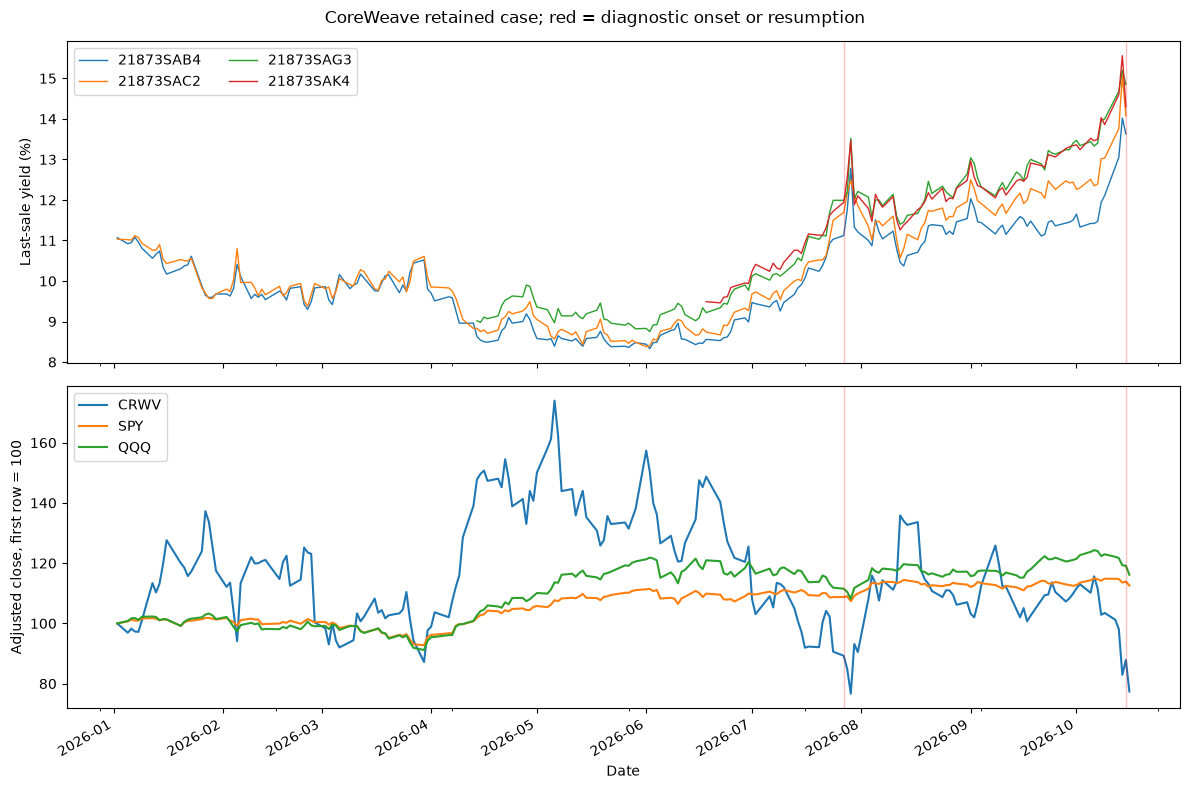

In [5]:
watch=funding_results.loc[funding_results.state=='FUNDING_VULNERABILITY']
print('Issuer:',case['issuer_name'])
print('Earliest loaded funding-watch disclosure:',watch.eligible_at.iloc[0] if len(watch) else 'None in loaded disclosures')
events=timeline.loc[timeline.onset_or_resumption,'date']
print('Diagnostic onsets/resumptions:',[str(x.date()) for x in events])
for row in context.to_dict('records'):
    print('Event:',str(row['date'].date()))
    for h in case['horizons']:
        value=row[f"{case['issuer']}_{h}_sessions_pct"]
        print(f"  Issuer change over {h} observed sessions: {value:+.2f}%" if pd.notna(value) else f"  {h}-session outcome: incomplete")
print('No reliable advance-warning or cross-issuer generalization claim follows from this one selected case.')
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
for cusip,g in diagnostics.groupby('cusip'):
    axes[0].plot(g.date,g.yield_pct,label=cusip,linewidth=1)
axes[0].set_ylabel('Last-sale yield (%)')
if len(diagnostics): axes[0].legend(ncol=2)
if len(equity): (100*equity/equity.iloc[0]).plot(ax=axes[1])
axes[1].set_ylabel('Adjusted close, first row = 100')
for event in events:
    for ax in axes: ax.axvline(event,color='red',alpha=.25,linewidth=1)
fig.suptitle(case['issuer_name']+' retained case; red = diagnostic onset or resumption')
plt.tight_layout()
plt.show()


## Applying this to future funding-dependent issuers

1. Create a new case with its own issuer identity, instrument ownership evidence, currency, reporting timezone, equity calendar/panel and hash-pinned source snapshot. The shipped case is an example of the contract, not a prediction template.
2. Collect dated financial disclosures, mandatory investment commitments, debt maturity buckets, facility conditions, cash restrictions and successful financing events. Reconcile periods and preserve evidence against the stress hypothesis.
3. Capture issuer and matched-peer OAS with delivery/correction vintages for the stricter credit test. Last-sale yields alone cannot establish issuer-specific credit deterioration. Match currency, maturity, seniority, credit quality and option treatment.
4. Obtain legally usable cash, drawable capacity, monthly receipts/capex/debt service and actual hedge schedules before running a company cash forecast. Capacity, future hedge requirements and annual buckets are not substitutes.
5. Declare exposure rules, costs, false-alarm measures and issuer/period holdouts before outcomes. Compare price-only, broad-credit and issuer-enriched rules on identical coverage. Keep prospective records separately and include failed cases.

The notebook is a research diagnostic, not an automated issuer screening service. None of these inputs is inferred from company resemblance. Missing information remains unknown; one issuer does not establish sector or index stress. The original cash scenarios, portfolio allocations and paper journal are untouched.


In [6]:
from research.credit_funding.model import credit_assessment
strict=credit_assessment([],manifest['created_at'])
print('Original qualified issuer OAS gate:',strict)
print('Frozen baseline:',verify_review_snapshot()['status'])


Original qualified issuer OAS gate: {'asof_utc': '2026-10-17T03:44:28.358154+00:00', 'kind': 'issuer', 'state': 'UNKNOWN', 'reason': 'Insufficient qualified prior history and persistence.', 'observations': 0}
Frozen baseline: VERIFIED_DATED_SNAPSHOT


## Cross-issuer test — amendment declared 18 October 2026

**Question:** does the unchanged warning rule give useful earlier warnings in other funding-dependent infrastructure companies? The declared convenience sample is Applied Digital (APLD), IREN, Nebius (NBIS) and Core Scientific (CORZ), plus Oracle (ORCL) and Equinix (EQIX) as mature infrastructure contrasts. These contrasts are not matched credit peers. APLD and CORZ also have commercial links to CoreWeave, so the observations are not economically independent.

The universe, January 1–October 16 window, 20 prior observations, three persistent observations, 100 bp widening and two distinct bonds from one legal borrower were written to `research/credit_funding/issuer_study_20261018.json` before fetching bond/equity outcomes. Issuer financing structures had already been inspected. Before outcomes, fixed-coupon instruments were selected by maturity then CUSIP, excluding floating-rate notes. This is a retrospective test on current-vintage data, **not a preregistered historical or untouched holdout backtest**. Current instrument searches may omit retired instruments; there is no survivorship-free universe claim.

**Amendments:** add hash-pinned evidence under `data/issuer_study_20261018/`, a separate comparison module, full exchange-session checks, source-linked funding facts, explicit censoring, price-only/base-rate comparisons and a missed-warning audit. The strict parser found five zero-price/missing-yield TRACE rows. A study adapter preserves these raw rows and marks them unavailable, invalidating their windows. It never fills prices. No thresholds or frozen model files changed.

The original portfolio notebooks, credit/funding notebook/model, protocols, journal and CoreWeave snapshot remain unchanged. The earlier review receipt describes the earlier version; this comparison is a separately declared extension.


In [7]:
"""Offline, fixed-rule cross-issuer diagnostic with explicit coverage and censoring."""
import hashlib
import json
from datetime import timedelta
from pathlib import Path
from urllib.parse import urlparse
import numpy as np
import pandas as pd
from research.credit_funding.issuer_replay import (
    inside, iso_date, daily_index, positive_int, bond_diagnostics, issuer_timeline,
)

STUDY_PATH = 'research/credit_funding/issuer_study_20261018.json'
STUDY_DATA = 'data/issuer_study_20261018'
WARNING = 'YIELD_WARNING_DIAGNOSTIC'


def prepare_bonds(raw):
    """Keep invalid observations as missing, invalidating their entire windows."""
    frame = raw.copy()
    required = {'cusip', 'tradeDate', 'lastSalePrice', 'lastSaleYield'}
    if not required.issubset(frame):
        raise ValueError('Missing bond columns')
    for field in ['lastSalePrice', 'lastSaleYield']:
        if frame[field].map(lambda x: isinstance(x, (bool, np.bool_))).any():
            raise ValueError('Boolean bond observation')
        frame[field] = pd.to_numeric(frame[field], errors='raise')
    invalid = (~np.isfinite(frame.lastSalePrice) | (frame.lastSalePrice <= 0)
               | ~np.isfinite(frame.lastSaleYield))
    frame.loc[invalid, ['lastSalePrice', 'lastSaleYield']] = np.nan
    return frame, int(invalid.sum())


def validate_prices(prices):
    result = prices.copy()
    result.index = daily_index(result.index)
    if not result.index.is_monotonic_increasing or result.empty or result.columns.has_duplicates:
        raise ValueError('Prices require unique columns and ordered daily observations')
    if any(result[c].map(lambda x: isinstance(x, (bool, np.bool_))).any() for c in result):
        raise ValueError('Boolean equity observation')
    result = result.apply(pd.to_numeric, errors='raise')
    if not np.isfinite(result.to_numpy()).all() or (result <= 0).any().any():
        raise ValueError('Missing/invalid equity observations; do not fill')
    return result


def forward_outcomes(prices, dates, symbol, horizons=(5, 20), threshold=-10):
    """Anchor at event close, exclude same-day moves, censor incomplete windows.

    minimum_close_pct is relative to the event close, not peak-to-trough drawdown.
    The event close is a descriptive anchor, not a verified executable entry.
    """
    prices = validate_prices(prices)
    if symbol not in prices or not horizons or len(set(horizons)) != len(horizons):
        raise ValueError('Invalid symbol or horizons')
    for h in horizons:
        positive_int(h, 'horizon')
    if isinstance(threshold, bool) or not np.isfinite(threshold) or not -100 < threshold < 0:
        raise ValueError('Loss threshold must be between -100 and zero')
    rows = []
    for date in daily_index(dates):
        if date not in prices.index:
            raise ValueError('Event must have an observed close')
        pos = prices.index.get_loc(date)
        for h in horizons:
            available = min(h, len(prices) - pos - 1)
            item = dict(issuer=symbol, date=date, horizon=h, observed_after=available,
                        complete=available == h, close_return_pct=np.nan,
                        minimum_close_pct=np.nan, loss_hit=None, excess_spy_pct=np.nan)
            if available == h:
                path = 100 * (prices[symbol].iloc[pos+1:pos+h+1] / prices[symbol].iloc[pos] - 1)
                item.update(close_return_pct=float(path.iloc[-1]), minimum_close_pct=float(path.min()),
                            loss_hit=bool(path.min() <= threshold))
                if 'SPY' in prices:
                    item['excess_spy_pct'] = float(path.iloc[-1] - 100 * (
                        prices.SPY.iloc[pos+h] / prices.SPY.iloc[pos] - 1))
            rows.append(item)
    columns = ['issuer', 'date', 'horizon', 'observed_after', 'complete',
               'close_return_pct', 'minimum_close_pct', 'loss_hit', 'excess_spy_pct']
    return pd.DataFrame(rows, columns=columns)


def disclosure_events(records, prices):
    """One event per declared issuer; no carrying stale balance sheets forward."""
    prices = validate_prices(prices)
    result, seen = [], set()
    for r in records:
        symbol = r['issuer']
        if symbol in seen or symbol not in prices:
            raise ValueError('Duplicate/unknown disclosure issuer')
        seen.add(symbol)
        published, start, end = [iso_date(r[k]) for k in ['published_on', 'period_start', 'period_end']]
        if start > end or end > published or r['units'] != 'USD millions':
            raise ValueError('Invalid disclosure period or units')
        if urlparse(r['source_url']).scheme != 'https':
            raise ValueError('Primary disclosure URL required')
        for key in ['operating_cash_flow', 'cash_capex', 'reported_debt']:
            value = r[key]
            if isinstance(value, bool) or not isinstance(value, (int, float)) or not np.isfinite(value):
                raise ValueError('Invalid funding input')
        if r['cash_capex'] < 0 or r['reported_debt'] < 0 or not r.get('debt_basis'):
            raise ValueError('Invalid capex/debt or missing debt basis')
        eligible = pd.Timestamp(published + timedelta(days=1))
        sessions = prices.index[prices.index >= eligible]
        gap = r['cash_capex'] - r['operating_cash_flow']
        result.append(dict(issuer=symbol, published_on=str(published), period_start=str(start), period_end=str(end),
            eligible_date=eligible, event_close=sessions[0] if len(sessions) else pd.NaT,
            historical_gap_usdm=gap, state='FUNDING_VULNERABILITY' if gap > 0 and r['reported_debt'] > 0 else 'NO_FLAG',
            source_url=r['source_url']))
    return pd.DataFrame(result)


def crash_audit(prices, symbol, timeline=None, threshold=-10, lookback=20):
    """Prior 1..20 closes only; unknown coverage is never a missed signal."""
    prices = validate_prices(prices)
    positive_int(lookback, 'lookback')
    returns = prices[symbol].pct_change(fill_method=None) * 100
    states = None
    if timeline is not None:
        dates = daily_index(timeline.date)
        if not dates.equals(prices.index) or not timeline.state.isin([WARNING, 'NO_QUORUM', 'UNKNOWN']).all():
            raise ValueError('Timeline must match the full equity calendar and valid states')
        states = timeline.set_index('date').state
    rows = []
    for date in returns.index[returns <= threshold]:
        pos = prices.index.get_loc(date)
        status, lead = 'NOT_EVALUABLE', np.nan
        if states is not None:
            prior = states.iloc[max(0, pos-lookback):pos]
            hits = prior.index[prior.eq(WARNING)]
            if len(hits):
                status, lead = 'PRIOR_WARNING', pos - prices.index.get_loc(hits[-1])
            elif len(prior) < lookback or prior.eq('UNKNOWN').any():
                status = 'UNKNOWN_PRIOR_COVERAGE'
            else:
                status = 'NO_PRIOR_WARNING'
        rows.append(dict(issuer=symbol, date=date, daily_return_pct=float(returns[date]),
                         bond_prior_status=status, latest_warning_lead_sessions=lead))
    return pd.DataFrame(rows, columns=['issuer','date','daily_return_pct','bond_prior_status','latest_warning_lead_sessions'])


def load_study(root, expected_manifest_sha=None):
    root = Path(root)
    directory = inside(root, STUDY_DATA)
    manifest_raw = (directory/'manifest.json').read_bytes()
    if expected_manifest_sha and hashlib.sha256(manifest_raw).hexdigest() != expected_manifest_sha:
        raise ValueError('Study manifest changed')
    manifest = json.loads(manifest_raw)
    plan = json.loads(inside(root, STUDY_PATH).read_text(encoding='utf-8'))
    required = {'selection.json','equity_adjusted.csv','funding_disclosures.json','bond_currency_sources.json'}
    required.update(s+'_instruments.json' for s in plan['candidates'])
    if not required.issubset(manifest['file_sha256']):
        raise ValueError('Unpinned study inputs')
    for name, digest in manifest['file_sha256'].items():
        if hashlib.sha256(inside(directory, name).read_bytes()).hexdigest() != digest:
            raise ValueError('Study evidence changed: ' + name)
    raw = inside(root, STUDY_PATH).read_bytes()
    if hashlib.sha256(raw).hexdigest() != manifest['study_sha256']:
        raise ValueError('Study declaration changed')
    plan = json.loads(raw)
    selection = json.loads((directory/'selection.json').read_text(encoding='utf-8'))
    if selection['study_sha256'] != manifest['study_sha256']:
        raise ValueError('Selection refers to a different plan')
    if set(selection['selection']) != set(plan['candidates']):
        raise ValueError('Selection must retain the declared universe')
    for symbol, choice in selection['selection'].items():
        if choice['bonds'] and symbol+'_bonds.csv' not in manifest['file_sha256']:
            raise ValueError('Unpinned bond input')
    prices = validate_prices(pd.read_csv(directory/'equity_adjusted.csv', index_col=0, parse_dates=True))
    if set(prices) != set(plan['candidates']) | {'SPY','QQQ'}:
        raise ValueError('Unexpected equity universe')
    if prices.index.min() < pd.Timestamp(plan['window'][0]) or prices.index.max() > pd.Timestamp(plan['window'][1]):
        raise ValueError('Equity outside study window')
    # Require full XNYS session coverage; this detects missing whole dates, not just NaNs.
    import exchange_calendars as xcals
    expected = pd.DatetimeIndex(xcals.get_calendar('XNYS').sessions_in_range(*plan['window']))
    if expected.tz is not None:
        expected = expected.tz_localize(None)
    if not prices.index.equals(expected):
        raise ValueError('Incomplete exchange-session panel; no synthetic replacement')
    funding = json.loads((directory/'funding_disclosures.json').read_text(encoding='utf-8'))
    if {r['issuer'] for r in funding['records']} != set(plan['candidates']):
        raise ValueError('Disclosure coverage must retain all candidates')
    return plan, selection['selection'], prices, funding, manifest


def disclosure_price_context(prices, disclosures):
    """Was weakness already visible by the disclosure's observed-close anchor?"""
    prices = validate_prices(prices)
    rows = []
    for r in disclosures.to_dict('records'):
        symbol, event = r['issuer'], r['event_close']
        if pd.isna(event):
            continue
        if symbol not in prices or event not in prices.index:
            raise ValueError('Disclosure context requires an observed symbol/date')
        p = prices[symbol]
        pos = p.index.get_loc(event)
        item = dict(issuer=symbol, event_close=event,
                    from_window_start_pct=100*(p.iloc[pos]/p.iloc[0]-1),
                    earlier_daily_10pct_falls_in_20_sessions=int(
                        p.pct_change(fill_method=None).iloc[max(1,pos-20):pos].le(-.10).sum()))
        for h in (5,20):
            item[f'change_to_anchor_over_previous_{h}_sessions_pct'] = (
                100*(p.iloc[pos]/p.iloc[pos-h]-1) if pos >= h else np.nan)
        rows.append(item)
    return pd.DataFrame(rows)


def summarize_arm(outcomes, symbol, arm):
    rows = []
    for h in (5,20):
        f = outcomes.loc[outcomes.horizon == h]
        complete = f.loc[f.complete]
        hits = int(complete.loss_hit.sum()) if len(complete) else 0
        rows.append(dict(issuer=symbol, arm=arm, horizon=h, events=len(f), complete=len(complete),
            censored=len(f)-len(complete), loss_hits=hits,
            loss_frequency_pct=100*hits/len(complete) if len(complete) else np.nan,
            no_loss_frequency_pct=100*(len(complete)-hits)/len(complete) if len(complete) else np.nan,
            mean_close_return_pct=complete.close_return_pct.mean()))
    return rows


def run_study(root, expected_manifest_sha=None):
    plan, selected, prices, funding, manifest = load_study(root, expected_manifest_sha)
    directory = inside(root, STUDY_DATA)
    disclosures = disclosure_events(funding['records'], prices)
    events, comparisons, crashes, coverage, instruments = [], [], [], [], []
    timelines = {}
    for symbol in plan['candidates']:
        choice = selected[symbol]
        metadata = pd.DataFrame(json.loads((directory/(symbol+'_instruments.json')).read_text(encoding='utf-8')))
        if metadata.cusip.duplicated().any():
            raise ValueError('Duplicate instrument metadata')
        chosen = metadata.loc[metadata.cusip.isin(choice['bonds'])].copy()
        if set(chosen.cusip) != set(choice['bonds']):
            raise ValueError('Missing ownership metadata')
        instruments.extend([dict(equity_symbol=symbol, **r) for r in chosen.to_dict('records')])
        timeline = None
        raw_rows = unavailable = 0
        if choice['bonds']:
            raw = pd.read_csv(directory/(symbol+'_bonds.csv'), dtype={'cusip':str})
            clean, unavailable = prepare_bonds(raw)
            raw_rows = len(raw)
            if not set(clean.cusip).issubset(choice['bonds']):
                raise ValueError('Unexpected bond history identifier')
            # A quoted Reg S/144A twin is never a second independent issue.
            if chosen.duplicated(['issuerName','maturityDate','couponRate']).any():
                raise ValueError('Duplicate economic issue')
            if not chosen.isConvertible.eq('N').all() or not chosen.couponType.eq('FXPV').all():
                raise ValueError('Ineligible bond type')
            if choice.get('legal_issuer'):
                if not chosen.issuerName.eq(choice['legal_issuer']).all():
                    raise ValueError('Mixed legal borrowers cannot establish quorum')
                currency = json.loads((directory/'bond_currency_sources.json').read_text(encoding='utf-8'))
                if currency['currency'] != 'USD' or not set(choice['bonds']).issubset(currency['sources']):
                    raise ValueError('Missing currency evidence')
                spec = dict(plan['rules'], issuer=symbol, bonds=choice['bonds'], bond_window=plan['window'])
                timeline = issuer_timeline(bond_diagnostics(clean, spec), prices.index, spec)
                timelines[symbol] = timeline
            else:
                # Validate each project separately without pretending its single issue meets quorum.
                for borrower, group in chosen.groupby('issuerName'):
                    ids = group.cusip.tolist()
                    if len(ids) >= plan['rules']['min_warning_bonds']:
                        raise ValueError('Coverage declaration needs review: potentially evaluable legal issuer')
                    spec = dict(plan['rules'], issuer=borrower, bonds=ids, min_warning_bonds=1, bond_window=plan['window'])
                    bond_diagnostics(clean.loc[clean.cusip.isin(ids)], spec)
        coverage.append(dict(issuer=symbol, role=choice['role'], bond_rows=raw_rows,
            unavailable_bond_rows=unavailable, equity_sessions=len(prices),
            last_bond_date=raw.tradeDate.max() if raw_rows else None,
            evaluable_sessions=int(timeline.state.ne('UNKNOWN').sum()) if timeline is not None else 0,
            unknown_or_ineligible_sessions=int(timeline.state.eq('UNKNOWN').sum()) if timeline is not None else len(prices),
            warning_sessions=int(timeline.state.eq(WARNING).sum()) if timeline is not None else None,
            warning_onsets=int(timeline.onset_or_resumption.sum()) if timeline is not None else None))
        arms = {'all_equity_days': prices.index,
                'price_only_minus5pct': prices.index[prices[symbol].pct_change(fill_method=None).le(-.05)]}
        if timeline is not None:
            arms.update(bond_warning_onsets=pd.DatetimeIndex(timeline.loc[timeline.onset_or_resumption,'date']),
                        eligible_nonwarning_days=pd.DatetimeIndex(timeline.loc[timeline.state.eq('NO_QUORUM'),'date']),
                        price_only_same_bond_coverage=prices.index[
                            prices[symbol].pct_change(fill_method=None).le(-.05) & timeline.state.ne('UNKNOWN').to_numpy()])
        disclosure = disclosures.loc[disclosures.issuer.eq(symbol)].iloc[0]
        arms['first_funding_watch'] = pd.DatetimeIndex([disclosure.event_close] if
            disclosure.state == 'FUNDING_VULNERABILITY' and pd.notna(disclosure.event_close) else [])
        for arm, dates in arms.items():
            result = forward_outcomes(prices, dates, symbol, plan['outcomes']['horizons'], plan['outcomes']['loss_threshold_pct'])
            comparisons.extend(summarize_arm(result, symbol, arm))
            if arm in ['first_funding_watch','bond_warning_onsets']:
                result['arm'] = arm
                events.append(result)
        crashes.append(crash_audit(prices, symbol, timeline, plan['outcomes']['loss_threshold_pct']))
    return dict(plan=plan, manifest=manifest, prices=prices, disclosures=disclosures,
                disclosure_context=disclosure_price_context(prices, disclosures),
                coverage=pd.DataFrame(coverage), instruments=pd.DataFrame(instruments),
                events=pd.DataFrame([row for f in events for row in f.to_dict('records')], columns=list(events[0])),
                comparison=pd.DataFrame(comparisons),
                crashes=pd.DataFrame([row for f in crashes for row in f.to_dict('records')], columns=list(crashes[0])), timelines=timelines,
                funding_records=pd.DataFrame(funding['records']))


In [8]:
STUDY_MANIFEST_SHA='6ee42702bb58c0d9d54395c0f5afd01c8771cb4be71163f6c7ab22f9e0ebca92'
study=run_study(ROOT,STUDY_MANIFEST_SHA)
print('Evidence snapshot:',study['manifest']['created_at'])
display(study['coverage'])
display(study['instruments'][['equity_symbol','cusip','issuerName','couponRate','maturityDate','isConvertible']])
print('Equity panel: complete XNYS sessions through',study['prices'].index.max().date())
print('TRACE histories stop on October 15; October 16 bond state is unavailable, not carried forward.')


Evidence snapshot: 2026-10-18T06:26:56.311129+00:00


,issuer,role,bond_rows,unavailable_bond_rows,equity_sessions,last_bond_date,evaluable_sessions,unknown_or_ineligible_sessions,warning_sessions,warning_onsets
0,APLD,"near peer; separate legal borrowers, one issue...",443,10,199,2026-10-15,0,199,NaN,NaN
1,IREN,near peer; retrieved debt is convertible; yiel...,0,0,199,None,0,199,NaN,NaN
2,NBIS,near peer; retrieved debt is convertible; yiel...,0,0,199,None,0,199,NaN,NaN
3,CORZ,"near peer; separate legal borrowers, one issue...",122,10,199,2026-10-15,0,199,NaN,NaN
4,ORCL,mature contrast,771,4,199,2026-10-15,175,24,0.0,0.0
5,EQIX,mature contrast,641,42,199,2026-10-15,175,24,0.0,0.0


,equity_symbol,cusip,issuerName,couponRate,maturityDate,isConvertible
0,APLD,00202DAA5,APLD COMPUTECO LLC,9.25,2030-12-15,N
1,APLD,03772CAA1,APLD COMPUTECO 2 LLC,6.75,2031-03-15,N
2,APLD,03790NAA5,APLD COMPUTECO 3 LLC,7.00,2031-06-15,N
3,CORZ,21874AAA4,CORE SCIENTIFIC INC NEW,12.50,2028-01-23,N
4,CORZ,21874LAA0,CORE SCIENTIFIC FIN I LLC,7.75,2031-05-15,N
5,ORCL,68389XCD5,ORACLE CORP,2.30,2028-03-25,N
6,ORCL,68389XCM5,ORACLE CORP,4.50,2028-05-06,N
7,ORCL,68389XCY9,ORACLE CORP,4.80,2028-08-03,N
8,ORCL,68389XDW2,ORACLE CORP,4.55,2029-02-04,N
9,EQIX,29444UBE5,EQUINIX INC,3.20,2029-11-18,N


Equity panel: complete XNYS sessions through 2026-10-16
TRACE histories stop on October 15; October 16 bond state is unavailable, not carried forward.


### What the bond test can and cannot evaluate

IREN and Nebius instruments retrieved in this search are convertible. Their embedded equity option makes their yield changes unsuitable for this unchanged straight-bond test. Applied Digital has one selected issue at each of three different ComputeCo borrowers. Core Scientific has a Finance I project issue; the selected older parent issue has no observations in this window. Reg S and 144A versions of the same debt are not independent bonds. These four peers remain **NOT EVALUABLE** for the two-bond rule, rather than receiving fabricated no-warning or successful-warning scores. Individual project histories are retained and structurally checked but are not pooled into a parent signal.

Oracle and Equinix each have four selected fixed-rate USD issues with verified legal-issuer identity and source-linked currency evidence. Current metadata does not establish historical security-master availability. Their sample has 175 evaluable equity sessions each; the remaining 24 sessions are unknown. Both are mature contrasts, so even a successful result would not validate the closer peers.


### Funding evidence and first loaded disclosure events

Each candidate contributes its first loaded financial statement published in 2026. The gap is cash capital investment minus signed operating cash flow over the same reported period. Periods and capex definitions differ, are shown explicitly, and are **not annualized or ranked as comparable gap magnitudes**. For this direction-only test, reported book debt or a disclosed positive debt component can establish debt > 0; those amounts are labelled and are never treated as principal schedules. This is an amendment to the input contract, not an alteration of the retained principal-based case.

Eligibility starts at midnight in New York on the calendar day after publication; the first subsequent observed close is the outcome anchor. Any loss on publication day or anchor day cannot be claimed as predicted by these results. The first loaded disclosure is not the earliest public indication of financing dependence. No stale state is carried forward and no future filing is used to reconstruct earlier cash availability.

Successful financing, customer prepayments, restricted cash and relevant caveats accompany every issuer. A cash investment gap is not evidence that financing failed or that a default is imminent.


**Timing review added after inspecting the initial outcome tables:** the price-context table shows changes up to the disclosure anchor and earlier daily falls within 20 sessions. It is descriptive context, not another fitted signal or a change to the declared success metric. It prevents an already-underway decline from being described as a newly predicted problem. Short prehistory remains blank. Changes to the anchor include the anchor session; the daily-fall count excludes that session.

In [9]:
display(study['disclosures'])
display(study['disclosure_context'])
display(study['funding_records'][['issuer','period_start','period_end','operating_cash_flow','cash_capex','reported_debt','debt_basis','capex_basis']])
for row in study['funding_records'].to_dict('records'):
    print(row['issuer'], '\n  Source:',row['source_url'],'\n  Locator:',row['locator'])
    print('  Funding support:',row['favourable_evidence'],'\n  Caveat:',row['caveat'])


,issuer,published_on,period_start,period_end,eligible_date,event_close,historical_gap_usdm,state,source_url
0,APLD,2026-01-07,2025-06-01,2025-11-30,2026-01-08,2026-01-08,899.358,FUNDING_VULNERABILITY,https://ir.applieddigital.com/sec-filings/all-...
1,IREN,2026-02-05,2025-07-01,2025-12-31,2026-02-06,2026-02-06,785.705,FUNDING_VULNERABILITY,https://www.sec.gov/Archives/edgar/data/187884...
2,NBIS,2026-02-12,2025-01-01,2025-12-31,2026-02-13,2026-02-13,3664.100,FUNDING_VULNERABILITY,https://assets.nebius.com/assets/2829268f-924f...
3,CORZ,2026-03-02,2025-01-01,2025-12-31,2026-03-03,2026-03-03,450.750,FUNDING_VULNERABILITY,https://investors.corescientific.com/sec-filin...
4,ORCL,2026-03-10,2025-06-01,2026-02-28,2026-03-11,2026-03-11,21813.000,FUNDING_VULNERABILITY,https://investor.oracle.com/investor-news/news...
5,EQIX,2026-02-11,2025-01-01,2025-12-31,2026-02-12,2026-02-12,400.000,FUNDING_VULNERABILITY,https://investor.equinix.com/news-events/press...


,issuer,event_close,from_window_start_pct,earlier_daily_10pct_falls_in_20_sessions,change_to_anchor_over_previous_5_sessions_pct,change_to_anchor_over_previous_20_sessions_pct
0,APLD,2026-01-08,13.625044,0,NaN,NaN
1,IREN,2026-02-06,-2.037468,3,-22.162262,-8.428193
2,NBIS,2026-02-13,8.960540,2,13.832757,-5.655292
3,CORZ,2026-03-03,-4.315194,0,-14.381648,-14.381648
4,ORCL,2026-03-11,-16.431879,0,7.055195,2.020133
5,EQIX,2026-02-12,25.357601,0,18.612853,19.880594


,issuer,period_start,period_end,operating_cash_flow,cash_capex,reported_debt,debt_basis,capex_basis
0,APLD,2025-06-01,2025-11-30,-97.868,801.490,2600.000,Rounded reported debt; positive-debt indicator...,"Property/equipment and other assets, gross cas..."
1,IREN,2025-07-01,2025-12-31,214.004,999.709,3745.699,Sum of five remaining convertible principal am...,720.001 property/equipment excluding hardware ...
2,NBIS,2025-01-01,2025-12-31,401.900,4066.000,4127.700,Balance-sheet current debt 24.5 plus non-curre...,Continuing operations property/equipment and i...
3,CORZ,2025-01-01,2025-12-31,278.250,729.000,1060.325,Noncurrent convertible and other notes carryin...,Cash purchases of property/plant/equipment; ex...
4,ORCL,2025-06-01,2026-02-28,17357.000,39170.000,134605.000,Current notes/borrowings 9887 plus noncurrent ...,"GAAP cash capital expenditures, nine months; n..."
5,EQIX,2025-01-01,2025-12-31,3911.000,4311.000,21417.000,Disclosed total debt principal including finan...,Purchases of other property/plant/equipment; r...


APLD 
  Source: https://ir.applieddigital.com/sec-filings/all-sec-filings/content/0001144879-26-000002/apldq226earningsrelease.htm 
  Locator: Cash flows, six months ended November 30, 2025; balance sheet commentary
  Funding support: Completed $2.35bn secured notes and drew preferred equity financing. Restricted cash is included in reported liquidity and is not all freely drawable. 
  Caveat: CoreWeave customer exposure connects this peer to the original case; separate ComputeCo entities secure different projects.
IREN 
  Source: https://www.sec.gov/Archives/edgar/data/1878848/000187884826000015/iren-20251231.htm 
  Locator: Cash flows (USD thousands converted /1000); note 16 remaining principal
  Funding support: Quarter-end cash $3,260.6m; company described $3.6bn GPU financing for Microsoft, conditional on final documentation and other terms. 
  Caveat: Mining transition and equity-linked debt differ from straight-bond credit risk. Acquisition copy obtained from Yahoo SEC mirror.
N

### Earlier-warning outcomes, adverse cases and base rates

The fixed loss target is a subsequent closing price at least 10% below the event close within the next 5 or 20 sessions. `minimum_close_pct` measures loss relative to the event close, **not** peak-to-trough maximum drawdown. A path can hit that loss threshold and still finish with a positive return. Final close returns and SPY-relative changes are therefore reported alongside the loss indicator. Full horizons are required; incomplete observations stay censored even if an early loss has already occurred.

The comparisons retain every equity day, a price-only alarm after a daily fall of at least 5%, and, where bonds qualify, eligible nonwarning dates and price-only alarms on the same bond coverage. These are descriptive base rates, not matched causal controls or achieved trading returns. Rolling windows overlap, adjacent price alarms can belong to one episode, and six first-disclosure events are too few for a reliable incremental-predictive claim. No threshold was optimized.


In [10]:
display(study['events'])
display(study['comparison'].loc[study['comparison'].horizon.eq(20)])
fund20=study['events'].loc[study['events'].arm.eq('first_funding_watch') & study['events'].horizon.eq(20)]
fund5=study['events'].loc[study['events'].arm.eq('first_funding_watch') & study['events'].horizon.eq(5)]
print('First-disclosure watches:',len(fund20),'20-session loss hits:',int(fund20.loss_hit.sum()),'5-session loss hits:',int(fund5.loss_hit.sum()))
print('Watches followed by a positive 20-session close change:',int(fund20.close_return_pct.gt(0).sum()))
near=['APLD','IREN','NBIS','CORZ']
base=study['comparison'].loc[study['comparison'].issuer.isin(near) & study['comparison'].arm.eq('all_equity_days') & study['comparison'].horizon.eq(20)]
print('Near-peer ordinary-date 20-session loss-hit frequency (overlapping descriptive windows):',round(100*base.loss_hits.sum()/base.complete.sum(),2),'%')
print('Two-bond warning onsets in the two evaluable contrasts:',int(study['coverage'].warning_onsets.sum()))
print('Conclusion: financing dependence is visible, but useful incremental early-warning performance is NOT established.')


,issuer,date,horizon,observed_after,complete,close_return_pct,minimum_close_pct,loss_hit,excess_spy_pct,arm
0,APLD,2026-01-08,5,5,True,10.269257,10.269257,False,9.873321,first_funding_watch
1,APLD,2026-01-08,20,20,True,9.423920,-12.820918,True,9.262939,first_funding_watch
2,IREN,2026-02-06,5,5,True,0.932344,-4.303139,False,2.216699,first_funding_watch
3,IREN,2026-02-06,20,20,True,-7.147984,-12.263927,True,-5.359746,first_funding_watch
4,NBIS,2026-02-13,5,5,True,2.652789,-0.499955,False,2.558908,first_funding_watch
5,NBIS,2026-02-13,20,20,True,32.486484,-11.437607,True,34.352259,first_funding_watch
6,CORZ,2026-03-03,5,5,True,1.045751,-2.875820,False,1.508774,first_funding_watch
7,CORZ,2026-03-03,20,20,True,-2.222223,-9.084969,False,1.924867,first_funding_watch
8,ORCL,2026-03-11,5,5,True,-6.265318,-6.265318,False,-4.062248,first_funding_watch
9,ORCL,2026-03-11,20,20,True,-15.190348,-15.190348,True,-15.994214,first_funding_watch


,issuer,arm,horizon,events,complete,censored,loss_hits,loss_frequency_pct,no_loss_frequency_pct,mean_close_return_pct
1,APLD,all_equity_days,20,199,179,20,134,74.860335,25.139665,-1.418335
3,APLD,price_only_minus5pct,20,37,33,4,24,72.727273,27.272727,1.164263
5,APLD,first_funding_watch,20,1,1,0,1,100.000000,0.000000,9.423920
7,IREN,all_equity_days,20,199,179,20,137,76.536313,23.463687,-0.767138
9,IREN,price_only_minus5pct,20,45,40,5,28,70.000000,30.000000,1.382877
11,IREN,first_funding_watch,20,1,1,0,1,100.000000,0.000000,-7.147984
13,NBIS,all_equity_days,20,199,179,20,107,59.776536,40.223464,12.017062
15,NBIS,price_only_minus5pct,20,35,31,4,19,61.290323,38.709677,14.412286
17,NBIS,first_funding_watch,20,1,1,0,1,100.000000,0.000000,32.486484
19,CORZ,all_equity_days,20,199,179,20,116,64.804469,35.195531,0.298319


First-disclosure watches: 6 20-session loss hits: 4 5-session loss hits: 0
Watches followed by a positive 20-session close change: 3
Near-peer ordinary-date 20-session loss-hit frequency (overlapping descriptive windows): 68.99 %
Two-bond warning onsets in the two evaluable contrasts: 0
Conclusion: financing dependence is visible, but useful incremental early-warning performance is NOT established.


The funding watch is followed by a 20-session loss-threshold hit in APLD, IREN, NBIS and ORCL, but not CORZ or EQIX; none hits the threshold within five sessions. APLD and NBIS finish the 20-session window higher despite interim losses. Because ordinary-date losses are already frequent in the volatile near peers, three hits among four near-peer disclosure events do not demonstrate skill. Oracle's subsequent decline is a useful case to retain, not evidence of a general predictive rule.

Neither mature contrast triggers a two-bond warning. There are subsequent 20-session loss windows on otherwise eligible nonwarning dates, so zero bond alarms cannot be presented as successful loss detection. No bond precision estimate exists when there are zero warning events. The closest peers cannot supply a fair two-bond recall estimate with the available instruments.


,issuer,date,daily_return_pct,bond_prior_status,latest_warning_lead_sessions
0,APLD,2026-01-30,-11.006038,NOT_EVALUABLE,NaN
1,APLD,2026-02-04,-14.059945,NOT_EVALUABLE,NaN
2,APLD,2026-02-05,-11.715287,NOT_EVALUABLE,NaN
3,APLD,2026-03-06,-10.501961,NOT_EVALUABLE,NaN
4,APLD,2026-03-30,-13.531145,NOT_EVALUABLE,NaN
5,APLD,2026-06-05,-10.260481,NOT_EVALUABLE,NaN
6,APLD,2026-07-29,-12.772357,NOT_EVALUABLE,NaN
7,APLD,2026-10-16,-11.476215,NOT_EVALUABLE,NaN
8,IREN,2026-01-30,-10.193848,NOT_EVALUABLE,NaN
9,IREN,2026-02-04,-17.374519,NOT_EVALUABLE,NaN


Daily falls of at least 10%, grouped without hiding ineligible issuers:


,,days
issuer,bond_prior_status,
APLD,NOT_EVALUABLE,8
CORZ,NOT_EVALUABLE,2
IREN,NOT_EVALUABLE,9
NBIS,NOT_EVALUABLE,12


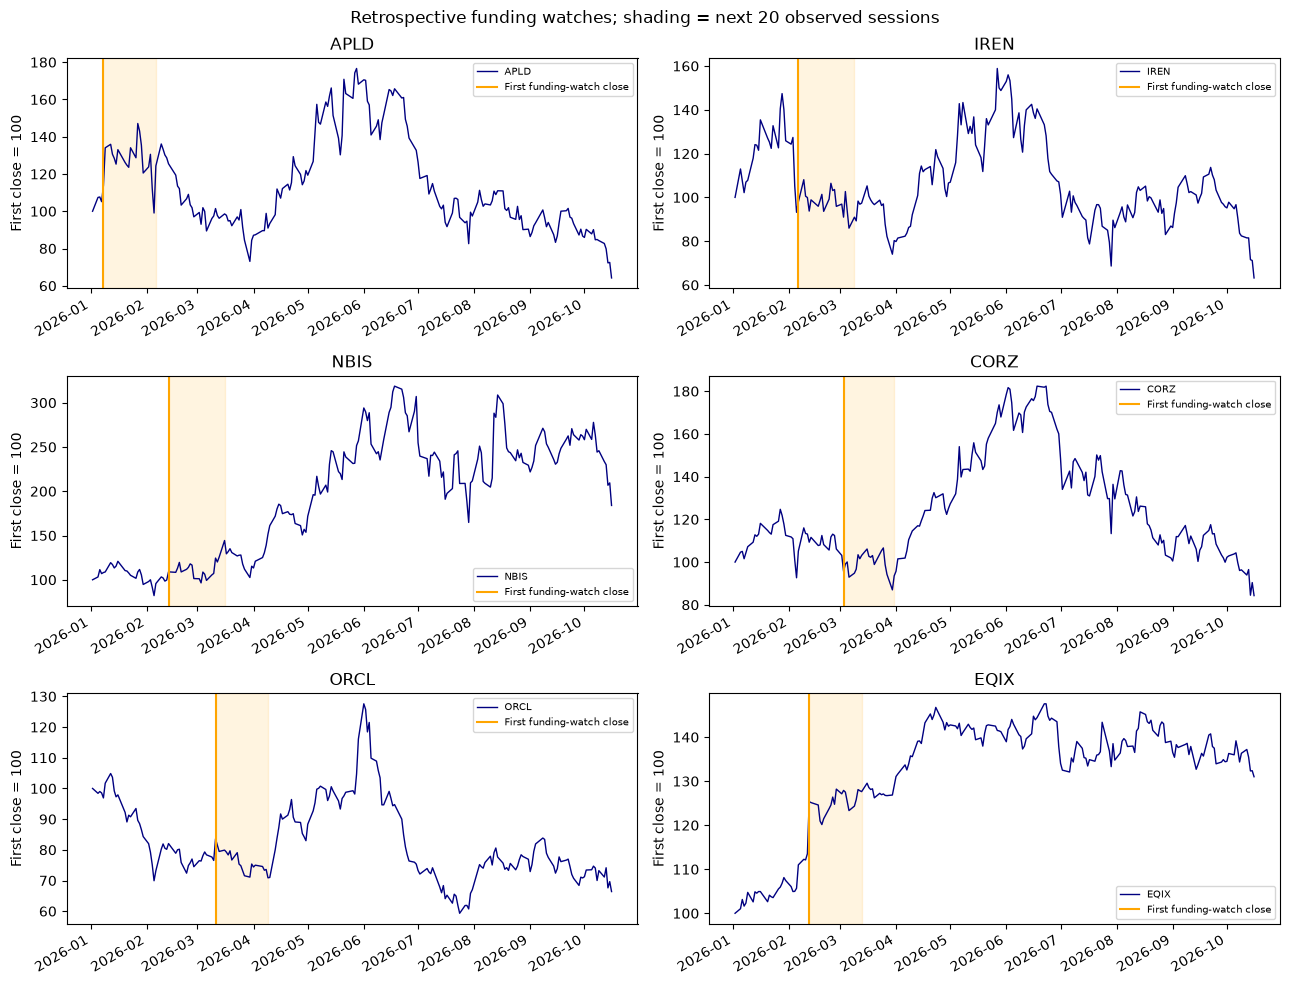

Frozen baseline verification: VERIFIED_DATED_SNAPSHOT


In [11]:
display(study['crashes'])
print('Daily falls of at least 10%, grouped without hiding ineligible issuers:')
display(study['crashes'].groupby(['issuer','bond_prior_status']).size().rename('days').to_frame())
import matplotlib.pyplot as plt
fig,axes=plt.subplots(3,2,figsize=(13,10))
for ax,row in zip(axes.flat,study['disclosures'].to_dict('records')):
    symbol=row['issuer'];p=study['prices'][symbol];event=row['event_close']
    (100*p/p.iloc[0]).plot(ax=ax,color='navy',linewidth=1)
    if pd.notna(event):
        ax.axvline(event,color='orange',label='First funding-watch close')
        pos=p.index.get_loc(event);ax.axvspan(event,p.index[min(pos+20,len(p)-1)],color='orange',alpha=.12)
    ax.set_title(symbol);ax.set_ylabel('First close = 100');ax.set_xlabel('')
    ax.legend(fontsize=7)
fig.suptitle('Retrospective funding watches; shading = next 20 observed sessions')
plt.tight_layout();plt.show()
print('Frozen baseline verification:',verify_review_snapshot()['status'])


### Interpretation and next evidence needed

The daily-crash audit asks whether a qualified bond diagnostic was present **1–20 prior sessions**, excluding the crash day. Missing prior coverage remains unknown. The 31 daily falls of at least 10% occur in the four structurally ineligible peers; the two evaluable contrasts have none. That prevents a meaningful cross-issuer daily-crash sensitivity estimate in this sample. The separate 20-session loss tables retain slower declines as well.

Keep the unchanged rule as a research watch, not an allocation or short-selling trigger. A stronger next study needs historical issuer/borrower mappings, credit spreads with option treatment for convertibles, matched credit/rates controls, dated receipt/correction vintages, and repeated nonoverlapping disclosure events. Freeze a broader issuer and time holdout before calibration. These retrospective results do not justify changing the frozen portfolio weights or backfilling the prospective paper journal.

Reproduce offline with `python run_issuer_credit_replay.py --publish`. Source URLs, request receipts, raw issuer-filtered FINRA responses, selection decisions and evidence hashes are packaged with this study. Whole financial publications and failed acquisition attempts remain local acquisition outputs; structured factual extracts and primary links are included. Results are unchanged by an unavailable live data service because notebook execution uses only the saved snapshot.


## Broader early-warning test — declared 18 October 2026

**Question.** Does issuer credit and funding information warn of equity stress earlier or more reliably than price-only and broad-credit signals, when every signal is scored on the same eligible issuer-sessions?

**What was declared, and when (UTC, 18 October 2026).** All times come from the files themselves.

| Time | Step | File |
|---|---|---|
| 11:10 | Protocol frozen: universe, targets, signals, periods, tests and success criteria | `research/credit_funding/early_warning_protocol_20261018.json` |
| 11:12 | Bond-identifier searches; abbreviated search terms added for seven issuers before any outcome | `data/early_warning_20261018/search_amendment.json` |
| 11:14 | Mechanical bond selection from FINRA metadata only. Version 2 replaced version 1, which preferred rarely traded Reg S twins; v1 is kept | `selection.json`, `selection_superseded_v1.json` |
| 11:17 | Equity identity and coverage checks; SATS, WBD and PARA excluded with reasons | `equity_quality.json` |
| 11:25 | All 1,801 evidence files pinned | `manifest.json` |
| 11:27 | Development phase (2022-2023) recorded once | `early_warning_development_receipt_20261018.json` |
| 11:31 | Holdout phase (2024 to 16 Oct 2026) recorded once | `early_warning_holdout_receipt_20261018.json` |

No threshold, horizon, universe member or signal definition changed after any outcome was computed. Bond histories and equity prices were downloaded only after the selection was written. Both phases ran on the same calculation module (SHA-256 `1442478b…`), recorded in each receipt.

**Universe.** 38 US-listed issuers in capital-intensive, debt-funded sectors (cable, telecom, towers, data centres, semiconductors, storage, energy, airlines, cruise, autos, casinos, power, steel), two mature cloud contrasts (AMZN, META) and four convertible-funded growth issuers (RIVN, LCID, PLUG, RUN). The seven issuers examined on 17-18 October (CRWV, APLD, IREN, NBIS, CORZ, ORCL, EQIX) are excluded: they are development evidence only.

**Target.** Nonoverlapping equity stress episodes: the first close at least 20% below the prior 60-session high, ending on recovery to 90% of that high or after 60 sessions. A warning must come 1 to 20 sessions before onset. Alarms on the onset day, or during an episode already under way, are reported separately and never counted as warnings. A secondary target applies the same rule to performance relative to SPY.

**Signals.** P1 is a daily fall of 5% or more and P2 a 10% drawdown from the 60-session high. B1 is ICE BofA US high-yield OAS and B2 the Moody's Baa-Treasury spread. I0 is the earlier frozen raw-yield rule and I1 the same rule applied to G-spreads (yield minus the interpolated Treasury curve). I2 adds an excess-over-index condition. F1 and F2 are funding watch and funding gap from 10-Q and 10-K filings. E1 and E2 combine P2 with I1 and F2. Each signal is dated by when its data was actually public: TRACE and ICE values the next session, filings the first close after SEC acceptance.

**Data and its limits.**

- **Bond prices:** FINRA TRACE end-of-day last sale for up to four straight fixed-coupon bonds per issuer, from one exact legal borrower. These are current-vintage downloads; the historical delivery times of these prints are unknown.
- **No OAS:** G-spreads are not option-adjusted. No free issuer OAS history was found.
- **Convertibles** are excluded from every spread, because their prices carry equity optionality.
- **Not pooled:** different legal borrowers are never combined to reach the two-bond quorum.
- **Guarantees and collateral:** FINRA metadata has no guarantor or collateral fields, so these are recorded as UNVERIFIED.
- **Equity and curve data:** prices are Yahoo adjusted closes in their current vintage. The Treasury curve and spread indices come from FRED in its current vintage. FRED serves ICE indices only from October 2023, so B1 is unavailable in development.
- **Funding data:** SEC XBRL company facts and the submissions index. Acceptance timestamps set when each filing becomes usable. These were added in a separate dated addendum after the author authorised a contact email at 12:30 UTC (see *Funding addendum* below). Restricted cash, undrawn facilities and financing proceeds are recorded but never counted as cash. SATS has no SEC CIK in the current ticker map.



### Audit of the six-issuer result

The earlier study reported a 10% interim loss within 20 sessions after four of six funding watches. The cell below asks how often that would happen with no information at all, using each issuer's own ordinary-day rate from the same table. The ordinary-day windows overlap, so this is an approximate benchmark, not an exact null.

In [12]:
from itertools import product
c20=study['comparison'].loc[study['comparison'].horizon.eq(20)&study['comparison'].arm.eq('all_equity_days')].set_index('issuer')
rates=(c20.loss_hits/c20.complete).reindex(['APLD','IREN','NBIS','CORZ','ORCL','EQIX'])
display(rates.rename('ordinary-day 20-session loss rate').to_frame())
p_ge4=sum(np.prod([r if h else 1-r for r,h in zip(rates,hits)]) for hits in product([0,1],repeat=6) if sum(hits)>=4)
print(f'Probability of at least 4 of 6 hits from ordinary-day rates alone: {p_ge4:.2f}')


,ordinary-day 20-session loss rate
issuer,
APLD,0.748603
IREN,0.765363
NBIS,0.597765
CORZ,0.648045
ORCL,0.452514
EQIX,0.011173


Probability of at least 4 of 6 hits from ordinary-day rates alone: 0.41


Other audit findings. The earlier study stays as published; these points qualify how it is read:

- **Selection.** The six issuers were picked after a visible AI-infrastructure sell-off, with their financing structures already inspected. That makes them development evidence, not a test.
- **The funding flag is close to a constant.** All six first disclosures were flagged. A flag that fires for every capital-intensive issuer describes the sector; it cannot time anything.
- **Overlapping windows.** The ordinary-day comparison uses 179 overlapping 20-session windows per issuer, which overstates how much independent evidence there is.
- **Raw yields mix rates and credit.** The 100 bp raw-yield rule responds to Treasury moves as well as issuer credit. The new study adds a G-spread version.
- **No calculation error was found.** Censoring, the next-day eligibility rule and the same-day exclusion behave as documented.


In [13]:
import json
from research.credit_funding import early_warning as ew
EW_MANIFEST_SHA='1553ccb6ec68324b10306e3a6eb9a28dda4afcb08689cddeb5f157c53a53cf78'
ew_inputs=ew.load(ROOT,EW_MANIFEST_SHA)
print('Evidence pinned at',ew_inputs['manifest']['created_at'],'| protocol',ew_inputs['manifest']['protocol_sha256'][:12])
display(pd.DataFrame([dict(issuer=k,status=v['status'],legal_issuer=v.get('legal_issuer'),bonds=len(v['bonds']),
    callable=sum(x=='Y' for x in v.get('callable',{}).values()),convertibles_excluded=len(v.get('convertible_cusips',[])))
    for k,v in ew_inputs['selection'].items()]))
print('Equity exclusions:',json.dumps(ew_inputs['quality']['reasons'],indent=1))


Evidence pinned at 2026-10-18T11:25:35.446016+00:00 | protocol 5c7cbf150516


,issuer,status,legal_issuer,bonds,callable,convertibles_excluded
0,CHTR,ELIGIBLE_ISSUER_CREDIT,CHARTER COMMUNICATIONS OPER LLC / CHARTER COMM...,4,4,0
1,LUMN,ELIGIBLE_ISSUER_CREDIT,LEVEL 3 FING INC,4,4,0
2,SATS,ELIGIBLE_ISSUER_CREDIT,DISH DBS CORP,3,2,3
3,T,ELIGIBLE_ISSUER_CREDIT,AT&T INC,4,2,0
4,VZ,ELIGIBLE_ISSUER_CREDIT,VERIZON COMMUNICATIONS INC,4,2,1
5,TMUS,ELIGIBLE_ISSUER_CREDIT,T-MOBILE USA INC,4,4,0
6,WBD,ELIGIBLE_ISSUER_CREDIT,WARNERMEDIA HLDGS INC,2,2,0
7,PARA,ELIGIBLE_ISSUER_CREDIT,PARAMOUNT SKYDANCE CORP,4,2,0
8,AMT,ELIGIBLE_ISSUER_CREDIT,AMERICAN TOWER CORP NEW,4,4,0
9,CCI,ELIGIBLE_ISSUER_CREDIT,CROWN CASTLE INTL CORP NEW,4,4,0


Equity exclusions: {
 "SATS": "Yahoo returned no history in the combined download or the single retry. Bond, funding and broad arms cannot be matched to equity outcomes; NOT_EVALUABLE.",
 "WBD": "Yahoo returned one row (2026-10-05) for the ticker, consistent with a delisted symbol whose history is no longer served. NOT_EVALUABLE; no substitute ticker spliced.",
 "PARA": "Ticker identity failure: the PARA series trades near 0.5-75 with repeated 50-97% daily jumps from 2024, inconsistent with Paramount; Paramount now trades as PSKY, for which Yahoo returned only 15 rows. NOT_EVALUABLE; no splice."
}


### Development (2022-2023) and holdout (2024 to 16 October 2026)

Both phases are recomputed here from the saved evidence and checked against their dated receipts. The holdout receipt was written once, after the development receipt, and neither phase changed a parameter. Permutation and bootstrap results are read from the receipts because they are slow to recompute.

Without funding data the declared primary sample is empty, so this section uses `common_no_funding`: the identical issuer-sessions on which the price, broad-credit and issuer-credit signals are all evaluable. In development it is almost empty because the ICE high-yield series on FRED starts in October 2023.

In [14]:
cols=['signal','issuer_sessions','alarm_onsets','hits','false_alarms','same_day','in_episode','censored',
      'precision_pct','episodes','warned','recall_pct','median_lead_sessions','false_per_250','persistence_sessions','base_rate_pct']
phase_tables={}
for phase in ['development','holdout']:
    receipt=json.loads((ROOT/f'research/credit_funding/early_warning_{phase}_receipt_20261018.json').read_text(encoding='utf-8'))
    got=ew.run_phase(ew_inputs,phase)
    saved=pd.DataFrame(receipt['results'])
    fresh=got['results'][saved.columns].reset_index(drop=True)
    pd.testing.assert_frame_equal(fresh.astype(float,errors='ignore').round(9),saved.astype(float,errors='ignore').round(9),check_dtype=False)
    phase_tables[phase]=dict(results=got['results'],dependence=pd.DataFrame(receipt['dependence_tests']),
        relative=pd.DataFrame(receipt['relative_results']),executed=receipt['executed_at'])
    print(phase,receipt['period'],'receipt',receipt['executed_at'],'reproduced exactly')
for phase in ['development','holdout']:
    r=phase_tables[phase]['results']
    for sample in ['common_no_funding','own_price']:
        print(f'{phase} | {sample}')
        display(r.loc[r['sample'].eq(sample),cols].round(2))


development ['2022-01-03', '2023-12-29'] receipt 2026-10-18T11:27:31.601799+00:00 reproduced exactly


holdout ['2024-01-02', '2026-10-16'] receipt 2026-10-18T11:31:53.975048+00:00 reproduced exactly
development | common_no_funding


,signal,issuer_sessions,alarm_onsets,hits,false_alarms,same_day,in_episode,censored,precision_pct,episodes,warned,recall_pct,median_lead_sessions,false_per_250,persistence_sessions,base_rate_pct
11,P1,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08
12,P2,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08
13,B1,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,3.94,1.08
14,B2,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08
15,I0,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,1.00,1.08
16,I1,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08
17,I2,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08
18,F1,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08
19,F2,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08
20,E1,428,0,0,0,0,0,0,NaN,0,0,NaN,NaN,0.0,NaN,1.08


development | own_price


,signal,issuer_sessions,alarm_onsets,hits,false_alarms,same_day,in_episode,censored,precision_pct,episodes,warned,recall_pct,median_lead_sessions,false_per_250,persistence_sessions,base_rate_pct
22,P1,17512,208,47,64,14,83,0,42.34,158,108,68.35,12.0,0.91,NaN,22.57
23,P2,17512,188,65,104,1,18,0,38.46,158,73,46.20,8.0,1.48,NaN,22.57
24,B1,17512,0,0,0,0,0,0,NaN,158,0,0.00,NaN,0.00,4.00,22.57
25,B2,17512,0,0,0,0,0,0,NaN,158,0,0.00,NaN,0.00,NaN,22.57
26,I0,17512,6,0,0,0,6,0,NaN,158,2,1.27,19.5,0.00,5.35,22.57
27,I1,17512,6,0,0,0,6,0,NaN,158,2,1.27,19.5,0.00,7.21,22.57
28,I2,17512,0,0,0,0,0,0,NaN,158,0,0.00,NaN,0.00,NaN,22.57
29,F1,17512,0,0,0,0,0,0,NaN,158,0,0.00,NaN,0.00,NaN,22.57
30,F2,17512,0,0,0,0,0,0,NaN,158,0,0.00,NaN,0.00,NaN,22.57
31,E1,17512,189,65,104,1,19,0,38.46,158,75,47.47,8.0,1.48,NaN,22.57


holdout | common_no_funding


,signal,issuer_sessions,alarm_onsets,hits,false_alarms,same_day,in_episode,censored,precision_pct,episodes,warned,recall_pct,median_lead_sessions,false_per_250,persistence_sessions,base_rate_pct
11,P1,10804,117,19,60,10,26,2,24.05,43,23,53.49,10.0,1.39,NaN,11.69
12,P2,10804,121,26,85,2,5,3,23.42,43,23,53.49,9.0,1.97,NaN,11.69
13,B1,10804,16,0,5,0,11,0,0.00,43,1,2.33,15.0,0.12,3.94,11.69
14,B2,10804,0,0,0,0,0,0,NaN,43,0,0.00,NaN,0.00,NaN,11.69
15,I0,10804,1,0,1,0,0,0,0.00,43,0,0.00,NaN,0.02,1.00,11.69
16,I1,10804,0,0,0,0,0,0,NaN,43,0,0.00,NaN,0.00,NaN,11.69
17,I2,10804,0,0,0,0,0,0,NaN,43,0,0.00,NaN,0.00,NaN,11.69
18,F1,10804,0,0,0,0,0,0,NaN,43,0,0.00,NaN,0.00,NaN,11.69
19,F2,10804,0,0,0,0,0,0,NaN,43,0,0.00,NaN,0.00,NaN,11.69
20,E1,10804,121,26,85,2,5,3,23.42,43,23,53.49,9.0,1.97,NaN,11.69


holdout | own_price


,signal,issuer_sessions,alarm_onsets,hits,false_alarms,same_day,in_episode,censored,precision_pct,episodes,warned,recall_pct,median_lead_sessions,false_per_250,persistence_sessions,base_rate_pct
22,P1,24535,252,53,116,20,59,4,31.36,185,125,67.57,13.0,1.18,NaN,16.64
23,P2,24535,291,74,185,4,20,8,28.57,185,98,52.97,10.0,1.89,NaN,16.64
24,B1,24535,35,0,9,0,26,0,0.00,185,3,1.62,7.0,0.09,4.00,16.64
25,B2,24535,0,0,0,0,0,0,NaN,185,0,0.00,NaN,0.00,NaN,16.64
26,I0,24535,1,0,1,0,0,0,0.00,185,0,0.00,NaN,0.01,5.35,16.64
27,I1,24535,0,0,0,0,0,0,NaN,185,0,0.00,NaN,0.00,7.21,16.64
28,I2,24535,0,0,0,0,0,0,NaN,185,0,0.00,NaN,0.00,NaN,16.64
29,F1,24535,0,0,0,0,0,0,NaN,185,0,0.00,NaN,0.00,NaN,16.64
30,F2,24535,0,0,0,0,0,0,NaN,185,0,0.00,NaN,0.00,NaN,16.64
31,E1,24535,291,74,185,4,20,8,28.57,185,98,52.97,10.0,1.89,NaN,16.64


**Reading the tables.** A *hit* is an alarm followed by a new stress episode 1 to 20 sessions later. *Same-day* alarms fire on the onset session and *in-episode* alarms fire while a drop is already under way; neither counts as a warning. *Base rate* is the share of ordinary eligible sessions followed by an onset within 20 sessions, so a signal is informative only if its precision clearly beats it.

In [15]:
h=phase_tables['holdout']
dep=h['dependence']
display(dep.loc[dep['sample'].eq('common_no_funding')].dropna(axis=1,how='all'))
print(json.dumps(ew.verdict(h['results'],dep,'common_no_funding'),indent=1,default=str))
rel=h['relative']
print('Secondary target: drawdown relative to SPY')
display(rel.loc[rel['sample'].eq('common_no_funding'),['signal','alarm_onsets','hits','false_alarms','same_day','in_episode','precision_pct','episodes','warned','recall_pct','base_rate_pct']].round(2))


,sample,signal,observed_precision,permutation_p,ci90_low_pp,ci90_high_pp,draws
14,common_no_funding,P1,0.243590,0.001000,NaN,NaN,NaN
15,common_no_funding,P2,0.236364,0.003498,NaN,NaN,NaN
16,common_no_funding,B1,0.000000,1.000000,NaN,NaN,NaN
17,common_no_funding,I0,0.000000,1.000000,NaN,NaN,NaN
18,common_no_funding,I1,NaN,NaN,NaN,NaN,NaN
19,common_no_funding,I2,NaN,NaN,NaN,NaN,NaN
20,common_no_funding,F1,NaN,NaN,NaN,NaN,NaN
21,common_no_funding,F2,NaN,NaN,NaN,NaN,NaN
22,common_no_funding,E2,NaN,NaN,NaN,NaN,NaN
23,common_no_funding,I1-P2,NaN,NaN,NaN,NaN,0.0


{
 "verdict": "INCONCLUSIVE_LOW_POWER",
 "reason": "I1 has fewer than 5 alarm onsets"
}
Secondary target: drawdown relative to SPY


,signal,alarm_onsets,hits,false_alarms,same_day,in_episode,precision_pct,episodes,warned,recall_pct,base_rate_pct
11,P1,117,19,54,11,32,26.03,47,22,46.81,14.08
12,P2,121,31,72,4,11,30.10,47,24,51.06,14.08
13,B1,16,1,7,0,8,12.50,47,2,4.26,14.08
14,B2,0,0,0,0,0,NaN,47,0,0.00,14.08
15,I0,1,0,1,0,0,0.00,47,0,0.00,14.08
16,I1,0,0,0,0,0,NaN,47,0,0.00,14.08
17,I2,0,0,0,0,0,NaN,47,0,0.00,14.08
18,F1,0,0,0,0,0,NaN,47,0,0.00,14.08
19,F2,0,0,0,0,0,NaN,47,0,0.00,14.08
20,E1,121,31,72,4,11,30.10,47,24,51.06,14.08


### How close did issuer spreads come to the rule?

With zero issuer alarms there is nothing to score, so the useful question is whether the rule was nearly reached and when. For each issuer the cell shows the largest holdout widening of the second-widest bond on any day, which is what the two-bond quorum needs to exceed 100 bp. This is descriptive and changes no rule.

In [16]:
_,_,ew_diag=ew.build_panel(ew_inputs)
rows=[]
for s,(d0,d1) in ew_diag.items():
    d=d1[(d1.date>='2024-01-02')&d1.state.ne('UNKNOWN')]
    q=d.groupby('date').minimum_widening_bp.apply(lambda x: x.nlargest(2).iloc[-1] if len(x)>=2 else np.nan) if len(d) else pd.Series(dtype=float)
    rows.append(dict(issuer=s,known_bond_days=len(d),widest_bond_bp=d.minimum_widening_bp.max() if len(d) else np.nan,
        second_bond_bp=q.max() if q.notna().any() else np.nan,date=q.idxmax() if q.notna().any() else None))
near=pd.DataFrame(rows).sort_values('second_bond_bp',ascending=False)
display(near.round(1))


,issuer,known_bond_days,widest_bond_bp,second_bond_bp,date
28,CZR,1987,103.4,96.9,2025-04-09
23,NCLH,402,121.1,86.4,2025-04-08
26,MGM,1798,97.3,67.7,2025-04-08
11,WDC,779,78.2,61.4,2025-04-08
21,CCL,1405,99.0,60.6,2025-04-08
25,GM,1763,68.7,56.0,2025-04-09
10,MU,1828,60.4,46.3,2025-04-14
9,INTC,2467,43.7,39.8,2024-08-14
20,UAL,283,38.8,34.8,2026-03-16
29,AES,980,46.9,33.3,2025-04-11


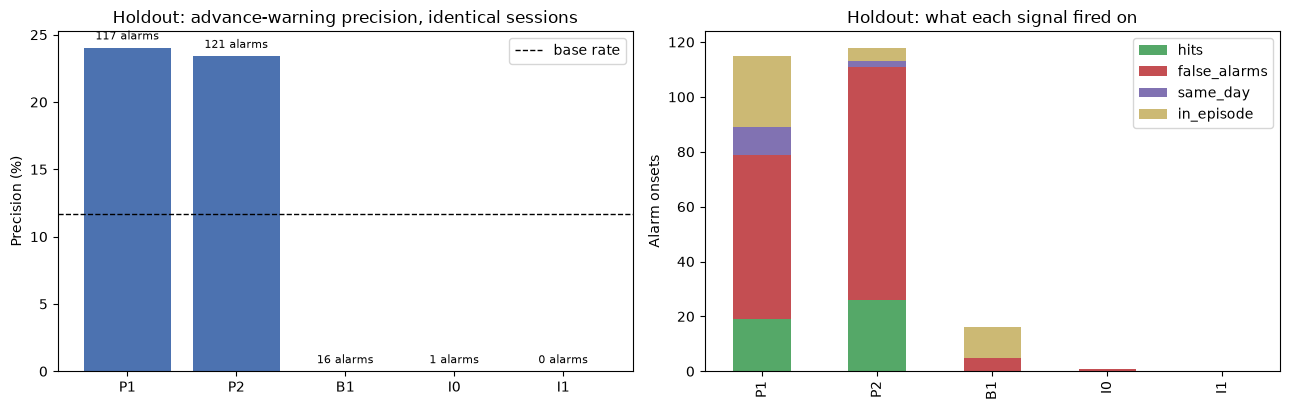

In [17]:
import matplotlib.pyplot as plt
r=h['results'].loc[h['results']['sample'].eq('common_no_funding')].set_index('signal')
show=['P1','P2','B1','I0','I1']
fig,axes=plt.subplots(1,2,figsize=(13,4.2))
ax=axes[0]
ax.bar(show,r.loc[show,'precision_pct'].fillna(0),color=['#4c72b0','#4c72b0','#dd8452','#55a868','#55a868'])
ax.axhline(r.base_rate_pct.iloc[0],color='k',ls='--',lw=1,label='base rate')
for i,s in enumerate(show):
    v=r.loc[s,'precision_pct']
    ax.text(i,(v if np.isfinite(v) else 0)+0.6,f"{int(r.loc[s,'alarm_onsets'])} alarms",ha='center',fontsize=8)
ax.set_ylabel('Precision (%)');ax.set_title('Holdout: advance-warning precision, identical sessions');ax.legend()
ax=axes[1]
r.loc[show,['hits','false_alarms','same_day','in_episode']].plot(kind='bar',stacked=True,ax=ax,
    color=['#55a868','#c44e52','#8172b2','#ccb974'])
ax.set_title('Holdout: what each signal fired on');ax.set_ylabel('Alarm onsets');ax.set_xlabel('')
plt.tight_layout();plt.show()


### Funding addendum: SEC filings, scored after the main holdout

Declared at 12:32 UTC after the author authorised an SEC contact header. The rules are unchanged from the 11:10 protocol, and the evaluator module is the same file. Both funding phases are recomputed here and checked against their receipts. `common` is now the declared primary sample: price, broad-credit, issuer-credit and funding signals all evaluable.

In [18]:
from research.credit_funding.early_warning_filings import load_addendum
ledger,usable,add_manifest=load_addendum(ROOT)
print('Filing ledger:',len(ledger),'records |',ledger.status.value_counts().to_dict())
fund_inputs=dict(ew_inputs); fund_inputs['filings']=usable
for phase in ['development','holdout']:
    receipt=json.loads((ROOT/f'research/credit_funding/early_warning_funding_{phase}_receipt_20261018.json').read_text(encoding='utf-8'))
    got=ew.run_phase(fund_inputs,phase)
    saved=pd.DataFrame(receipt['results'])
    pd.testing.assert_frame_equal(got['results'][saved.columns].reset_index(drop=True).astype(float,errors='ignore').round(9),
        saved.astype(float,errors='ignore').round(9),check_dtype=False)
    print(phase,'funding receipt',receipt['executed_at'],'reproduced exactly')
    if phase=='holdout':
        fh=got['results']; fdep=pd.DataFrame(receipt['dependence_tests'])
display(fh.loc[fh['sample'].eq('common'),cols].round(2))
display(fdep.loc[fdep['sample'].eq('common')].dropna(axis=1,how='all'))
print('Funding verdict:',json.dumps(ew.verdict(fh,fdep,'common',issuer_signal='F2'),indent=1,default=str))
print('Issuer-credit verdict on the primary sample:',ew.verdict(fh,fdep,'common')['verdict'])
display(usable.loc[usable.alarm_session.ge('2024-01-02'),['issuer','form','period_end','acceptance_local','alarm_session','ttm_ocf_usd','ttm_capex_usd','unrestricted_cash_usd','debt_usd','F1','F2']].tail(8))
posthoc=json.loads((ROOT/'research/credit_funding/early_warning_funding_posthoc_20261018.json').read_text(encoding='utf-8'))
print(posthoc['label']); print(json.dumps(posthoc['results'],indent=1))


Filing ledger: 2234 records | {'OK': 1947, 'TTM_NOT_CONSTRUCTIBLE': 186, 'MISSING_CASH_FLOW_TAGS': 85, 'OLDER_PERIOD_REVISION': 16}


development funding receipt 2026-10-18T12:36:25.003265+00:00 reproduced exactly


holdout funding receipt 2026-10-18T12:38:38.292930+00:00 reproduced exactly


,signal,issuer_sessions,alarm_onsets,hits,false_alarms,same_day,in_episode,censored,precision_pct,episodes,warned,recall_pct,median_lead_sessions,false_per_250,persistence_sessions,base_rate_pct
0,P1,7685,83,16,41,8,18,0,28.07,37,20,54.05,9.5,1.33,NaN,14.48
1,P2,7685,91,21,66,2,2,0,24.14,37,19,51.35,8.0,2.15,NaN,14.48
2,B1,7685,13,0,4,0,9,0,0.00,37,0,0.00,NaN,0.13,3.92,14.48
3,B2,7685,0,0,0,0,0,0,NaN,37,0,0.00,NaN,0.00,NaN,14.48
4,I0,7685,1,0,1,0,0,0,0.00,37,0,0.00,NaN,0.03,1.00,14.48
5,I1,7685,0,0,0,0,0,0,NaN,37,0,0.00,NaN,0.00,NaN,14.48
6,I2,7685,0,0,0,0,0,0,NaN,37,0,0.00,NaN,0.00,NaN,14.48
7,F1,7685,28,3,18,1,6,0,14.29,37,3,8.11,12.0,0.59,NaN,14.48
8,F2,7685,5,0,4,0,1,0,0.00,37,0,0.00,NaN,0.13,NaN,14.48
9,E1,7685,91,21,66,2,2,0,24.14,37,19,51.35,8.0,2.15,NaN,14.48


,sample,signal,observed_precision,permutation_p,ci90_low_pp,ci90_high_pp,draws
0,common,P1,0.285714,0.001999,NaN,NaN,NaN
1,common,P2,0.244186,0.028486,NaN,NaN,NaN
2,common,B1,0.000000,1.000000,NaN,NaN,NaN
3,common,I0,0.000000,1.000000,NaN,NaN,NaN
4,common,I1,NaN,NaN,NaN,NaN,NaN
5,common,I2,NaN,NaN,NaN,NaN,NaN
6,common,F1,0.142857,0.684158,NaN,NaN,NaN
7,common,F2,0.000000,1.000000,NaN,NaN,NaN
8,common,E2,0.000000,1.000000,NaN,NaN,NaN
9,common,I1-P2,NaN,NaN,NaN,NaN,0.0


Funding verdict: {
 "verdict": "NOT_ESTABLISHED",
 "checks": [
  {
   "criterion": "a",
   "signal": "F2",
   "precision_gain_pp": -24.137931034482758,
   "ci90_low_pp": -34.1069518717,
   "permutation_p": 1.0,
   "passed": false
  },
  {
   "criterion": "a",
   "signal": "E2",
   "precision_gain_pp": -24.137931034482758,
   "ci90_low_pp": -34.1069518717,
   "permutation_p": 1.0,
   "passed": false
  },
  {
   "criterion": "b",
   "signal": "E1",
   "added_warned_episodes": 0,
   "added_false_alarms": 0,
   "passed": false
  }
 ]
}
Issuer-credit verdict on the primary sample: INCONCLUSIVE_LOW_POWER


,issuer,form,period_end,acceptance_local,alarm_session,ttm_ocf_usd,ttm_capex_usd,unrestricted_cash_usd,debt_usd,F1,F2
2226,WYNN,10-Q,2024-09-30,2024-11-04T22:00:42-05:00,2024-11-05,1.388504e+09,406055000.0,2.407289e+09,1.178656e+10,NO_FLAG,NO_FLAG
2227,WYNN,10-K,2024-12-31,2025-02-13T22:00:42-05:00,2025-02-14,1.426203e+09,419929000.0,2.426155e+09,1.054173e+10,NO_FLAG,NO_FLAG
2228,WYNN,10-Q,2025-03-31,2025-05-06T21:00:26-04:00,2025-05-07,1.244883e+09,482158000.0,2.070086e+09,1.055310e+10,NO_FLAG,NO_FLAG
2229,WYNN,10-Q,2025-06-30,2025-08-07T21:03:12-04:00,2025-08-08,1.297185e+09,553789000.0,1.984752e+09,1.054479e+10,NO_FLAG,NO_FLAG
2230,WYNN,10-Q,2025-09-30,2025-11-06T22:21:15-05:00,2025-11-07,1.353665e+09,616424000.0,1.486291e+09,1.056819e+10,NO_FLAG,NO_FLAG
2231,WYNN,10-K,2025-12-31,2026-03-02T21:13:13-05:00,2026-03-03,1.352653e+09,660433000.0,1.463442e+09,1.054681e+10,NO_FLAG,NO_FLAG
2232,WYNN,10-Q,2026-03-31,2026-05-07T20:47:06-04:00,2026-05-08,1.372334e+09,679566000.0,1.187644e+09,1.052450e+10,NO_FLAG,NO_FLAG
2233,WYNN,10-Q,2026-06-30,2026-08-06T20:07:16-04:00,2026-08-07,1.459197e+09,667323000.0,1.573353e+09,1.072466e+10,NO_FLAG,NO_FLAG


POST-HOC EXPLORATORY, not a declared test. Chosen after reading the funding receipts.
{
 "development": {
  "ci90": [
   0.4831253492270438,
   51.67328835582207
  ],
  "perm_obs": 0.6666666666666666,
  "perm_p": 0.009495252373813094,
  "issuers_with_scored_E2": 9,
  "hits_by_issuer": {
   "NCLH": 5,
   "RCL": 4,
   "CCL": 2,
   "DLR": 1,
   "LCID": 1,
   "PLUG": 1
  },
  "dates": [
   "2022-02",
   "2022-03",
   "2022-04",
   "2022-09",
   "2022-11",
   "2022-12",
   "2023-02",
   "2023-03",
   "2023-07",
   "2023-08"
  ]
 },
 "holdout": {
  "ci90": [
   -4.709572401490582,
   34.8686785850965
  ],
  "perm_obs": 0.4666666666666667,
  "perm_p": 0.15542228885557222,
  "issuers_with_scored_E2": 9,
  "hits_by_issuer": {
   "LCID": 6,
   "NCLH": 2,
   "CLF": 2,
   "RCL": 1,
   "RIVN": 1,
   "PLUG": 1
  },
  "dates": [
   "2024-01",
   "2024-04",
   "2024-07",
   "2024-09",
   "2024-12",
   "2025-02",
   "2025-05",
   "2025-07",
   "2025-10",
   "2026-02",
   "2026-05",
   "2026-07",
   "20



### Findings

**1. The earlier four-of-six result carries no evidence of skill.** Using each issuer's own ordinary-day rate of a 10% interim loss within 20 sessions (APLD 75%, IREN 77%, NBIS 60%, CORZ 65%, ORCL 45%, EQIX 1%), four or more hits out of six would happen by chance about 41% of the time.

**2. The issuer credit rule never fired in the untouched holdout.** Across 10,804 issuer-sessions on which price, broad-credit and issuer-credit signals were all evaluable (26 of the 31 bond-eligible issuers had any evaluable coverage, 2024 to 16 October 2026), the G-spread rule I1 produced zero alarms. The raw-yield rule I0 produced one, a false alarm. The verdict under the frozen criteria is **INCONCLUSIVE_LOW_POWER**: there is too little issuer-credit activity to score, and certainly no demonstrated improvement. The closest approach was Caesars on 9 April 2025, when its second-widest bond widened 97 bp, during the tariff sell-off and not before it.

**3. Broad credit stress arrived with equity stress, not before it.** The high-yield OAS rule fired on one date, 9 April 2025. Because it is market-wide, that one date appears as 16 issuer alarms on the identical sample. Eleven of them fell inside episodes already under way, five were false alarms, and none was an advance hit. This is one event, not sixteen pieces of evidence.

**4. Price-only signals beat random timing, partly by construction.** On the same sessions, P1 and P2 had precision of 24% and 23% against a base rate of 12%. Within-issuer circular-shift permutation tests gave p = 0.001 and 0.0035. These tests compare against random alarm timing, not against simply being in a drawdown. P2 fires at a 10% fall from the same 60-session high that defines the 20% target, so part of its edge is mechanical. Each warned 23 of 43 episodes, with a median lead of 9 to 10 sessions. They are still noisy: P2 raised about two false alarms per 250 issuer-sessions, and three of four price alarms were not followed by an episode. The SPY-relative target gives the same ordering, with P2 at 30% precision against a 14% base rate.

**5. Development (2022-2023) showed the same pattern.** On each issuer's own bond coverage (the common sample is empty in development), all six issuer-credit alarm onsets fired during episodes already under way. None was an advance hit. They were coincident, not leading.

### What this does and does not show

- This is retrospective evidence on current-vintage data. It is not prospective validation, and nothing here changes portfolio weights or the prospective paper journal.
- Zero issuer alarms means the frozen rule (100 bp over a 20-observation median, persisting three observations, on two bonds) is too insensitive for 2024-26 conditions in these issuers. It does not prove that issuer spreads carry no information. A more sensitive rule would need a new declaration and new untouched data, because these holdout dates have now been seen.
- Coverage is uneven. TRACE prints for many high-yield bonds are too sparse for the four-day gap rule. For AAL, CLF, DVN and part of APA, the selection still chose Reg S international CUSIPs because no registered or 144A twin appeared in the search, and those rarely print. Several issuers (STX, APA, DVN, AAL, CLF, SBAC) have little or no evaluable issuer-credit coverage, and they stay unknown, not "no warning".
- The main holdout used the three-family sample `common_no_funding`; the funding addendum then scored the declared four-family primary sample. Both are reported.

### Funding addendum (declared 12:32 UTC, scored after the main holdout)

The funding rules F1, F2 and E2 were frozen at 11:10 with everything else. They are scored here without change on the declared primary sample: sessions where the price, broad-credit, issuer-credit and funding signals are all evaluable. The parser was corrected before any filing was parsed. The SEC download began 23 seconds before the declaration was written, but nothing was read until 12:34 (`funding_addendum/declaration.json`). The declaration's parser hash covers the parsing logic; the manifest's hash also covers the I/O helpers appended afterwards. The holdout price episodes had already been seen, so this addendum cannot be tuned, but it is not blind to the episode set.

- **Coverage:** 2,234 periodic filings in the ledger, 781 of them accepted inside the panel (June 2021 onward). Older filings map onto the first panel session, but they are superseded and stale before the development period starts, so they affect no scored number. Unknown states come from missing debt tags (292), missing cash-flow tags (85) and trailing twelve-month totals that cannot be built (186). A missing cash tag leaves the funding watch known and makes only the funding gap unknown.
- **Holdout result on the declared primary sample** (7,685 issuer-sessions, 37 episodes, base rate 14.5%):
  - The funding watch F1 fired 28 times, with 3 hits and 18 false alarms. Its precision of 14% equals the base rate (permutation p = 0.68).
  - The funding gap F2 fired 5 times with no hits.
  - Price alarms filtered by funding or credit state (E2) fired 6 times with no hits.
  - On the same sessions, the price signals P1 and P2 had precision of 28% and 24% (p = 0.002 and 0.029).
- **Verdict under the frozen criteria:** funding information is **NOT_ESTABLISHED** as an improvement, and issuer credit stays **INCONCLUSIVE_LOW_POWER**.
- **One post-hoc lead, which is not a declared test.** On each issuer's own funding coverage, a wider sample that includes convertible-funded issuers, price alarms during an active funding gap were right more often than price alarms alone. Holdout: 13 of 29 (45%) against 61 of 209 (29%). Development: 14 of 21 (67%) against 53 of 137 (39%).
  - In the holdout the gain is not significant. The issuer-bootstrap 90% interval runs from −5 to +35 points, and the permutation p is 0.16.
  - It is also concentrated. Lucid supplies 6 of the 13 holdout hits. In development, 11 of the 14 hits are cruise lines in 2022, which is one sector shock, so the development p of 0.009 is not independent evidence.
  - Because the issuer-credit rule never fired in the holdout, E2 there is simply "price alarm during an active funding gap".
  - It was chosen after reading the receipts, so it can only be validated prospectively or on new issuers. It is saved separately in `early_warning_funding_posthoc_20261018.json`.

### Independent review notes (after the holdout run)

An independent read-only review found no blocking error. Timing, sample identity, episode logic and every number above were checked against the receipts. It raised non-blocking points, which are disclosed here instead of rerunning the recorded phases:

- **Recall counts alarm days that fall inside an earlier episode.** This contradicts the in-episode rule. It explains why B1 shows one "warned" episode with zero hits, and why development I0/I1 show two warned episodes. Precision, the decision metric, is unaffected.
- **The permutation statistic is computed within the period, on issuers with at least 81 eligible sessions.** Its observed precision is 24.4% and 23.6%, slightly different from the table.
- **Development alarms in late December 2023 can be scored against January 2024 onsets.** These are price outcomes only and do not touch any rule.
- **I2 treats a missing high-yield value as "no excess" rather than unknown.** I2 never had an I1 alarm to filter, so this has no effect here.
- **The bootstrap resamples issuers with no eligible sessions.** This widens intervals slightly.
- **The SEC parser has edge cases to fix before the funding arm is scored:** 52/53-week years, a tag mismatch between YTD and annual values, multi-line capex, and amended filings for older periods. The parser has not yet run on real data.
- **The consolidated-subsidiary condition is enforced only by a declared exclusion list.** It is not checked against the filings.

### What would be needed to go further

1. Test the post-hoc funding-gap filter prospectively, or on issuers and dates not used here, with its rule frozen first.
2. Obtain issuer and peer OAS with dated vintages. This likely means a licensed source, which needs approval.
3. Obtain historical guarantor, collateral and legal-borrower mappings, for example from indentures.
4. Run any new, more sensitive spread rule prospectively, or on a later period nobody has examined.


In [19]:
print('Frozen baseline verification:',verify_review_snapshot()['status'])

Frozen baseline verification: VERIFIED_DATED_SNAPSHOT
